Setup

In [1]:
import os, re, glob, json, zipfile, tempfile, warnings
import numpy as np, pandas as pd
import statsmodels.api as sm
import matplotlib
import matplotlib.pyplot as plt
import maketables as mt
from scipy import stats
import xml.etree.ElementTree as ET
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 200)
REPO = os.path.abspath(os.path.join(os.getcwd(), "..", "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
assert os.path.isdir(os.path.join(REPO, "data", "raw")), "run from code/notebooks/ or the repo root"
D = os.path.join(REPO, "data", "raw", "lseg", "panel_2005_2026")
D12 = os.path.join(REPO, "data", "raw", "lseg", "panel_2012_2026")
EV = os.path.join(REPO, "data", "input", "omxsb")
FI = os.path.join(REPO, "data", "raw", "fi")
DER = os.path.join(REPO, "data", "derived", "fi")
OUT = os.path.join(REPO, "output", "omxsb_replication_2007")
ORIG = os.path.join(REPO, "output", "omxsb_replication", "tables", "tab_02_car_long.csv")
PHASE1 = os.path.join(REPO, "output", "omxsb_replication_2007", "tables", "tab_02_car_long_phase1.csv")
TAB = os.path.join(OUT, "tables")
FIG = os.path.join(OUT, "figures")
for p in [OUT, TAB, FIG, DER]:
    os.makedirs(p, exist_ok=True)
PANEL = os.path.join(D, "stocks_daily_2005.parquet")
STATIC = os.path.join(D, "stocks_static_2005.csv")
STATIC12 = os.path.join(D12, "stocks_static.csv")
INDEX = os.path.join(D, "indices_daily (1).csv")
EVENTS = os.path.join(EV, "omxsb_events_with_ric_2007_2026.csv")
REQ = [PANEL, STATIC, INDEX, EVENTS, STATIC12, ORIG, PHASE1]
ZIPS = sorted(glob.glob(os.path.join(FI, "Fondinnehav_*.zip")))
missing = [f for f in REQ if not os.path.exists(f)]
assert not missing, missing
assert len(ZIPS) == 31, len(ZIPS)
PER = ["2007–2012", "2013–2017", "2018–2020", "2021–2023", "2024–2026"]
BINS = [2006, 2012, 2017, 2020, 2023, 2026]
PER_OLD = PER[1:]
NPER_WORD = {4: "four", 5: "five"}[len(PER)]
STYLE = {"font.family": "serif", "font.size": 10, "axes.labelsize": 10, "axes.titlesize": 10, "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False, "lines.linewidth": 1.4, "figure.figsize": (6.3, 3.6), "figure.dpi": 150, "savefig.bbox": "tight", "savefig.pad_inches": 0.02, "axes.unicode_minus": False}
PALETTE = ["#000000", "#6E6E6E", "#B0B0B0", "#1F4E79"]
LS = [dict(color=PALETTE[2], linestyle="-"), dict(color=PALETTE[0], linestyle="-"), dict(color=PALETTE[0], linestyle="--"), dict(color=PALETTE[1], linestyle="-"), dict(color=PALETTE[3], linestyle="-.")]
plt.rcParams.update(STYLE)
LABELS = {"car": "CAR, AD−1 to ED+1 (%)", "ann": "Announcement window [AD−1, AD+1]", "eff": "Effective window [ED−1, ED+1]", "tot": "Total window [AD−1, ED+1]", "turn": "Excess turnover (monthly volume / shares)", "size": "Size (% of top-100 market cap)", "vol": "Volatility (sum of squared daily AR, %)", "nt": "Net trading by index funds (% of shares)", "instbuy": "Net trading by all funds (% of shares)", "activebuy": "Net trading by non-index funds (% of shares)", "indexown": "Index-fund ownership before AD (% of shares)", "addition": "Additions", "deletion": "Deletions"}
LABELS.update({p: p for p in PER})
TEX = {"tab_width": None, "tabcolsep": "5pt", "data_addlinespace": "0.25ex"}
STARS = "* p<0.10, ** p<0.05, *** p<0.01."
NUM = {}
MAN = []
def star(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""
def fig_save(fig, name, desc):
    fig.savefig(os.path.join(FIG, name + ".pdf"), format="pdf")
    fig.savefig(os.path.join(FIG, name + ".png"), format="png", dpi=300)
    MAN.append((name, desc))
    plt.show()
    plt.close(fig)
def tex_fix(path):
    s = open(path).read()
    s = re.sub(r"(?<!\\)%", r"\\%", s)
    s = re.sub(r"(\\\\)\s*\[", r"\1{}[", s)
    s = re.sub(r"(?<!\\)\{(-?\d+\.\d+)\}", lambda m: "\\{" + m.group(1) + "\\}", s)
    s = re.sub(r"\^(?=[G(])", r"\\textasciicircum{}", s)
    s = s.replace("−", "$-$").replace("η", "$\\eta$").replace("R²", "R$^2$")
    open(path, "w").write(s)
def tab_save(t, name, desc, df=None):
    t.save("tex", os.path.join(TAB, name + ".tex"), show=False, replace=True, tex_style=TEX)
    tex_fix(os.path.join(TAB, name + ".tex"))
    t.save("docx", os.path.join(TAB, name + ".docx"), show=False, replace=True)
    if df is not None:
        df.to_csv(os.path.join(TAB, name + ".csv"))
    MAN.append((name, desc))
    return t
pd.DataFrame({"file": [os.path.basename(f) for f in REQ + ZIPS], "mb": [round(os.path.getsize(f) / 1e6, 1) for f in REQ + ZIPS]})

,file,mb
0,stocks_daily_2005.parquet,143.4
1,stocks_static_2005.csv,0.1
2,indices_daily (1).csv,0.9
3,omxsb_events_with_ric_2007_2026.csv,0.2
4,stocks_static.csv,0.1
5,tab_02_car_long.csv,0.0
6,tab_02_car_long_phase1.csv,0.0
7,Fondinnehav_2018Q4_2022-11-16 17.05.zip,4.9
8,Fondinnehav_2019Q1_2022-11-16 17.35.zip,4.8
9,Fondinnehav_2019Q2_2022-11-16 15.35.zip,4.8


In [2]:
ev = pd.read_csv(EVENTS, parse_dates=["announcement_date", "effective_date"])
n_file = len(ev)
nocov = ev[ev.RIC.isna() | (ev.days_with_price < 10)].copy()
ev = ev[~ev.index.isin(nocov.index)].copy()
print(f"{n_file} events in {os.path.basename(EVENTS)}; {len(nocov)} without a RIC or with fewer than 10 days with a close between AD-3 and ED+3 are dropped before the sample filter ({int((nocov.effective_date < '2013-01-01').sum())} of them with effective dates before 2013)")
st = pd.read_csv(STATIC, parse_dates=["first_date", "last_date", "RetireDate"])
px = pd.read_parquet(PANEL) if PANEL.endswith(".parquet") else pd.read_csv(PANEL, parse_dates=["date"])
px["date"] = pd.to_datetime(px.date).astype("datetime64[ns]")
span = px.groupby("ric").date.agg(first_date="min", last_date="max", n_days="size")
n_bad = int((st.set_index("ric").first_date != span.reindex(st.ric).first_date.values).sum())
st = st.drop(columns=["first_date", "last_date", "n_days"]).merge(span, left_on="ric", right_index=True, how="left")
print(f"first_date, last_date and n_days in {os.path.basename(STATIC)} equal the pull range rather than the first and last trading day for {n_bad} of {len(st)} RICs; all three are recomputed from the daily panel")
st12 = pd.read_csv(STATIC12).set_index("ric")
fill = st.IssueISIN.isna() & st.ric.isin(st12.index[st12.IssueISIN.notna()])
for c in ["IssueISIN", "DTSubjectName"]:
    st[c] = st[c].where(~fill, st.ric.map(st12[c]))
print(f"IssueISIN and DTSubjectName taken from {os.path.basename(D12)}/stocks_static.csv for {int(fill.sum())} RICs that are missing from td_universe.csv: " + ", ".join(st.ric[fill]))
ix = pd.read_csv(INDEX, parse_dates=["date"])
assert set(ev.RIC) <= set(st.ric) and set(ev.RIC) <= set(px.ric)
pd.DataFrame({"rows": [len(ev), len(st), len(px), len(ix)], "cols": [ev.shape[1], st.shape[1], px.shape[1], ix.shape[1]]}, index=["events", "static", "daily", "indices"])

536 events in omxsb_events_with_ric_2007_2026.csv; 31 without a RIC or with fewer than 10 days with a close between AD-3 and ED+3 are dropped before the sample filter (31 of them with effective dates before 2013)
first_date, last_date and n_days in stocks_static_2005.csv equal the pull range rather than the first and last trading day for 1609 of 2117 RICs; all three are recomputed from the daily panel
IssueISIN and DTSubjectName taken from panel_2012_2026/stocks_static.csv for 169 RICs that are missing from td_universe.csv: ACADEbta.ST^L17, ACADEil.ST^C24, ACADEil.ST^C25, ACADEil.ST^C26, ACADEsr.ST^C24, ACADEsr.ST^C25, ACADEsr.ST^C26, ACADEtr.ST^L17, ACCNOK.ST^J25, ADEANOK.ST^J19, ADENOK.ST^F24, AECO.ST, AFbtab.ST^D19, AFtrb.ST^D19, AGASNOK.ST^H25, AINMTNOK.ST^L22, AIRXNOK.ST^B26, AKBMNOK.ST^J26, AKELd.ST^D25, AKHNOK.ST^D26, ALGETANOK.ST^C14, AMSCNOK.ST^K25, ANORANOK.ST^A22, ARCUSNOK.ST^I21, ARGEONOK.ST^H25, ASTKNOK.ST^C24, ATLANOK.ST^A21, AVMNOK.ST^E20, AWDRNOK.ST^L22, BANONOK.ST^K21,

,rows,cols
events,505,13
static,2117,8
daily,4340104,11
indices,32775,3


Sample

In [3]:
cal = pd.DatetimeIndex(ix.loc[(ix.ric == ".OMXSBGI") & ix.close.notna(), "date"].sort_values().unique())
pend = px.date.max()
def nxt(d):
    return cal[cal.searchsorted(d)]
ev["AD"] = ev.announcement_date.map(nxt)
ev["ED"] = ev.effective_date.map(nxt)
ev = ev.merge(st[["ric", "first_date", "last_date", "IssueISIN", "DTSubjectName"]], left_on="RIC", right_on="ric", how="left").drop(columns="ric")
ev["period"] = pd.cut(ev.ED.dt.year, BINS, labels=PER).astype(str)
assert ev.period.isin(PER).all()
ev["ad_moved"] = ev.AD != ev.announcement_date
ev["ed_moved"] = ev.ED != ev.effective_date
ev["listed_100"] = ev.first_date > ev.ED - pd.Timedelta(days=100)
ev["delisted_100"] = (ev.last_date < ev.ED + pd.Timedelta(days=100)) & (ev.last_date < pend)
ev[ev.ad_moved | ev.ed_moved][["event_id", "announcement_date", "AD", "effective_date", "ED"]]

,event_id,announcement_date,AD,effective_date,ED


In [4]:
drop = ev[ev.listed_100 | ev.delisted_100]
drop[["event_id", "company", "RIC", "type", "AD", "ED", "first_date", "last_date", "listed_100", "delisted_100"]]

,event_id,company,RIC,type,AD,ED,first_date,last_date,listed_100,delisted_100
20,OMXSB-2008H2-09,HEXPOL AB ser. B,HPOLb.ST,deletion,2008-06-11,2008-07-01,2008-06-09,2026-10-23,True,False
27,OMXSB-2009JAN-08,Loomis AB ser. B,LOOMIS.ST,deletion,2008-12-11,2009-01-02,2008-12-09,2026-10-23,True,False
31,OMXSB-2009JAN-12,Teleca AB ser. B,TELCb.ST^C09,deletion,2008-12-11,2009-01-02,2004-07-01,2009-03-02,False,True
33,OMXSB-2009JAN-14,Vostok Gas Ltd. SDB,VGASsdb.ST^A09,deletion,2008-12-11,2009-01-02,2004-07-01,2009-01-30,False,True
126,OMXSB-2014H1-02,Hemfosa Fastigheter AB,HEMF.ST^B20,addition,2014-05-08,2014-06-02,2014-03-21,2020-01-31,True,False
168,OMXSB-2016H2-01,Ahlsell AB,AHSL.ST^C19,addition,2016-11-10,2016-12-01,2016-10-28,2019-03-06,True,False
182,OMXSB-2017H1-01,Ambea AB,AMBEA.ST,addition,2017-05-09,2017-06-01,2017-03-31,2026-10-23,True,False
239,OMXSB-2019H1-05,Nordic Entertainment Group ser. B,VPLAYb.ST,addition,2019-05-13,2019-06-03,2019-03-28,2026-10-26,True,False
251,OMXSB-2019H2-03,EQT AB,EQTAB.ST,addition,2019-11-11,2019-12-02,2019-09-24,2026-10-23,True,False
256,OMXSB-2019H2-08,Hembla AB ser. B,HEMb.ST^A20,deletion,2019-11-11,2019-12-02,2014-04-09,2020-01-10,False,True


In [5]:
ev_all = ev.copy()
nc = nocov.assign(period=pd.cut(nocov.effective_date.dt.year, BINS, labels=PER).astype(str)).groupby(["period", "type"]).size().unstack().reindex(index=PER, columns=["addition", "deletion"]).fillna(0).astype(int)
n0 = ev.groupby(["period", "type"]).size().unstack().reindex(index=PER, columns=["addition", "deletion"]).fillna(0).astype(int)
ev = ev[~(ev.listed_100 | ev.delisted_100)].copy()
n1 = ev.groupby(["period", "type"]).size().unstack().reindex(index=PER, columns=["addition", "deletion"]).fillna(0).astype(int)
t1 = pd.concat({"In event list": n0 + nc, "With price data": n0, "After filter": n1}, axis=1)
t1.loc["Total"] = t1.sum()
t1.columns = pd.MultiIndex.from_tuples([(a, LABELS[b]) for a, b in t1.columns])
t1.index.name = "Period"
NUM["events_file"] = int((n0 + nc).values.sum())
NUM["events_raw"] = int(n0.values.sum())
NUM["events_sample"] = int(n1.values.sum())
NUM["events_dropped"] = int(len(drop))
NUM["events_no_price"] = int(len(nocov))
tab_save(mt.MTable(t1, notes="Number of OMXSB index additions and deletions by period of the effective date: all events in the list, events whose stock has at least 10 days with a closing price in the LSEG panel between three days before the announcement and three days after the effective date, and events remaining after dropping those where the stock was listed within 100 days before, or delisted within 100 days after, the effective date. Periods follow the year of the effective date. Events without price data are stocks that are not in the LSEG panel, which was pulled for the 2013-2026 constituents, or whose LSEG identifier could not be matched; they are listed in output/omxsb_replication_2007/coverage_failures.csv."), "tab_01_sample", "Event counts by period before and after the price-coverage and listing/delisting filters", t1)

In event list 
 
 
 With price data 
 
 
 After filter 
 
 
 
 Additions 
 Deletions 
 Additions 
 Deletions 
 Additions 
 Deletions 
 
 
 
 
 2007–2012 
 62 
 80 
 49 
 62 
 49 
 58 
 
 
 2013–2017 
 60 
 36 
 60 
 36 
 57 
 36 
 
 
 2018–2020 
 53 
 40 
 53 
 40 
 51 
 39 
 
 
 2021–2023 
 63 
 55 
 63 
 55 
 59 
 54 
 
 
 2024–2026 
 46 
 41 
 46 
 41 
 45 
 39 
 
 
 Total 
 284 
 252 
 271 
 234 
 261 
 226 
 
 
 Number of OMXSB index additions and deletions by period of the effective date: all events in the list, events whose stock has at least 10 days with a closing price in the LSEG panel between three days before the announcement and three days after the effective date, and events remaining after dropping those where the stock was listed within 100 days before, or delisted within 100 days after, the effective date. Periods follow the year of the effective date. Events without price data are stocks that are not in the LSEG panel, which was pulled for the 2013-2026 constituents, or whose LSEG identifier could not be matched; they are listed in output/omxsb_replication_2007/coverage_failures.csv.

Returns

In [6]:
px = px[px.date.isin(cal) & px.ric.str.contains(r"\.ST", regex=True)].sort_values(["ric", "date"]).reset_index(drop=True)
im = ix.pivot(index="date", columns="ric", values="close").reindex(cal)
rm = im.pct_change() * 100
def rser(ric, fill):
    g = px[px.ric == ric].set_index("date")
    r = (g.totret).fillna(g.close.pct_change() * 100)
    idx = cal[(cal >= g.index.min()) & (cal <= g.index.max())]
    r = r.reindex(idx)
    return r.fillna(0.0) if fill else r
RICS = ev_all.RIC.unique()
R = pd.DataFrame({ric: rser(ric, False) for ric in RICS}).reindex(cal)
R0 = pd.DataFrame({ric: rser(ric, True) for ric in RICS}).reindex(cal)
AR = R.sub(rm[".OMXSBGI"], axis=0)
AR2 = R.sub(rm[".OMXSGI"], axis=0)
AR0 = R0.sub(rm[".OMXSBGI"], axis=0)
pos = pd.Series(np.arange(len(cal)), index=cal)
def wsum(A, ric, a, b):
    s = A[ric].iloc[a:b + 1]
    return np.nan if s.isna().any() else s.sum()
for df in [ev, ev_all]:
    df["iAD"] = df.AD.map(pos).astype(int)
    df["iED"] = df.ED.map(pos).astype(int)
    for nm, A in [("", AR), ("_gi", AR2), ("_fill", AR0)]:
        df["ann" + nm] = [wsum(A, r, a - 1, a + 1) for r, a in zip(df.RIC, df.iAD)]
        df["eff" + nm] = [wsum(A, r, e - 1, e + 1) for r, e in zip(df.RIC, df.iED)]
        df["tot" + nm] = [wsum(A, r, a - 1, e + 1) for r, a, e in zip(df.RIC, df.iAD, df.iED)]
    df["ndays_tot"] = df.iED - df.iAD + 3
    df["adx"] = df.AD.dt.strftime("%Y-%m-%d")
n_na = {w: int((ev[w + "_fill"].notna() & ev[w].isna()).sum()) for w in ["ann", "eff", "tot"]}
NUM["windows_nan_instead_of_zero"] = n_na
print("Missing stock-days inside the listing range are kept as NaN rather than filled with a zero return, so an event drops out of a window that contains such a day; event-windows that change from a number to NaN: " + ", ".join(f"{w} {n}" for w, n in n_na.items()) + f" (of {len(ev)} events in the sample)")
print(ev[ev.tot_fill.notna() & ev.tot.isna()][["event_id", "company", "RIC", "type", "AD", "ED", "tot_fill"]].to_string(index=False))
n_nogi = int(ev.tot_gi.isna().sum())
print(f".OMXSGI starts {rm['.OMXSGI'].dropna().index.min().date()}: {n_nogi} events have no CAR against .OMXSGI ({int((ev.tot_gi.isna() & ev.tot.notna()).sum())} of them with a CAR against .OMXSBGI) and are left out of the .OMXSGI appendix table")
ev[["ann", "eff", "tot", "ann_gi", "eff_gi", "tot_gi", "ndays_tot"]].describe().T

Missing stock-days inside the listing range are kept as NaN rather than filled with a zero return, so an event drops out of a window that contains such a day; event-windows that change from a number to NaN: ann 1, eff 3, tot 6 (of 487 events in the sample)
       event_id                         company            RIC     type         AD         ED  tot_fill
OMXSB-2007H2-05 Tanganyika Oil Company Ltd. SDB TYKSsdb.ST^L08 addition 2007-06-12 2007-07-02 18.017493
OMXSB-2008H1-03 Svenska Cellulosa AB SCA ser. A        SCAa.ST addition 2007-12-14 2008-01-02  2.850058
OMXSB-2008H2-06      Atrium Ljungberg AB ser. B      ATRLJb.ST addition 2008-06-11 2008-07-01 24.459904
OMXSB-2010H1-07   Lundin Mining Corporation SDB LUMIsdb.ST^F17 addition 2010-05-07 2010-06-01 -3.294793
OMXSB-2018H1-07                Africa Oil Corp.         MER.ST deletion 2018-05-08 2018-06-01  8.331921
OMXSB-2018H2-10                Veoneer Inc. SDB  VNEsdb.ST^D22 addition 2018-11-12 2018-12-03 -1.558547
.OMXSGI starts 

,count,mean,std,min,25%,50%,75%,max
ann,486.0,-0.057841,5.375688,-42.735093,-2.162509,-0.140872,2.324098,47.307717
eff,484.0,-0.127069,5.239758,-26.619464,-2.515402,0.071785,2.230600,45.790764
tot,481.0,0.283841,9.968589,-43.301675,-4.320281,0.391957,5.201092,77.058373
ann_gi,473.0,-0.032938,5.399414,-42.501447,-2.120188,-0.066295,2.357037,47.339486
eff_gi,473.0,-0.137008,5.186838,-26.606107,-2.408569,0.050776,2.165411,46.161526
tot_gi,470.0,0.310116,9.965821,-43.270248,-4.093254,0.615462,5.173684,77.360194
ndays_tot,487.0,14.669405,4.585218,9.000000,9.000000,17.000000,18.500000,21.000000


Table 2

In [7]:
def ols(y, X, g):
    n, k = X.shape
    XtXi = np.linalg.inv(X.T @ X)
    b = XtXi @ X.T @ y
    e = y - X @ b
    Vh = XtXi @ (X.T @ (X * (e ** 2)[:, None])) @ XtXi * n / (n - k)
    gs = pd.factorize(g)[0]
    G = gs.max() + 1
    S = np.zeros((k, k))
    for j in range(G):
        u = X[gs == j].T @ e[gs == j]
        S += np.outer(u, u)
    Vc = XtXi @ S @ XtXi * G / (G - 1) * (n - 1) / (n - k)
    return b, e, Vh, Vc, G, gs, XtXi
WEBB = np.array([-np.sqrt(1.5), -1.0, -np.sqrt(0.5), np.sqrt(0.5), 1.0, np.sqrt(1.5)])
def p_floor(G):
    return 2 / 6 ** G if G < 12 else 1 / 2 ** (G - 1)
def floor_note(Gs):
    return " The wild cluster bootstrap uses 9,999 draws with the null imposed, Webb six-point weights when there are fewer than 12 clusters and Rademacher weights otherwise; the smallest attainable p-value is 2/6^G with Webb and 1/2^(G−1) with Rademacher weights, here " + "; ".join(f"G = {g}: {p_floor(g):.2g}" for g in Gs) + "."
def wcb(y, X, g, r, q=0.0, B=9999, seed=0):
    n, k = X.shape
    b, e, Vh, Vc, G, gs, XtXi = ols(y, X, g)
    r = np.asarray(r, float)
    t = (r @ b - q) / np.sqrt(r @ Vc @ r)
    br = b - XtXi @ r * ((r @ b - q) / (r @ XtXi @ r))
    er = y - X @ br
    A = np.stack([X[gs == j].T @ er[gs == j] for j in range(G)], axis=1)
    Q = np.stack([X[gs == j].T @ X[gs == j] for j in range(G)])
    rng = np.random.default_rng(seed)
    w = rng.choice(WEBB if G < 12 else np.array([-1.0, 1.0]), size=(B, G))
    dl = (XtXi @ A @ w.T).T
    sc = w[:, :, None] * A.T[None, :, :] - np.einsum("gkl,bl->bgk", Q, dl)
    S = np.einsum("bgk,bgl->bkl", sc, sc)
    V = XtXi @ S @ XtXi * G / (G - 1) * (n - 1) / (n - k)
    ts = (dl @ r) / np.sqrt(np.einsum("k,bkl,l->b", r, V, r))
    return t, np.mean(np.abs(ts) >= abs(t)), G
def cell(y, g):
    y = np.asarray(y, float)
    k = np.isfinite(y)
    y, g = y[k], np.asarray(g)[k]
    X = np.ones((len(y), 1))
    b, e, Vh, Vc, G, gs, _ = ols(y, X, g)
    th = b[0] / np.sqrt(Vh[0, 0])
    tc = b[0] / np.sqrt(Vc[0, 0])
    t, pw, G = wcb(y, X, g, [1.0])
    return dict(mean=b[0], se_hc1=np.sqrt(Vh[0, 0]), p_hc1=2 * stats.norm.sf(abs(th)), se_cr1=np.sqrt(Vc[0, 0]), p_cr1=2 * stats.t.sf(abs(tc), G - 1), p_wcb=pw, N=len(y), G=G)
def diffcell(y, g, d):
    y = np.asarray(y, float)
    k = np.isfinite(y)
    y, g, d = y[k], np.asarray(g)[k], np.asarray(d, float)[k]
    X = np.column_stack([1 - d, d]).astype(float)
    b, e, Vh, Vc, G, gs, _ = ols(y, X, g)
    r = np.array([-1.0, 1.0])
    th = r @ b / np.sqrt(r @ Vh @ r)
    tc = r @ b / np.sqrt(r @ Vc @ r)
    t, pw, G = wcb(y, X, g, r)
    return dict(mean=r @ b, se_hc1=np.sqrt(r @ Vh @ r), p_hc1=2 * stats.norm.sf(abs(th)), se_cr1=np.sqrt(r @ Vc @ r), p_cr1=2 * stats.t.sf(abs(tc), G - 1), p_wcb=pw, N=len(y), G=G)
def ftest(y, g, per, pers=None):
    pers = PER if pers is None else pers
    y = np.asarray(y, float)
    k = np.isfinite(y)
    y, g, per = y[k], np.asarray(g)[k], pd.Series(np.asarray(per)[k])
    X = pd.get_dummies(per).reindex(columns=pers).values.astype(float)
    b, e, Vh, Vc, G, gs, _ = ols(y, X, g)
    q = len(pers) - 1
    Rm = (np.eye(len(pers))[:-1] - np.eye(len(pers))[1:]).astype(float)
    W = (Rm @ b) @ np.linalg.solve(Rm @ Vc @ Rm.T, Rm @ b)
    F = W / q
    return F, stats.f.sf(F, q, G - 1), G
rows = []
for typ in ["addition", "deletion"]:
    for win in ["ann", "eff", "tot"]:
        s = ev[(ev.type == typ)]
        for p in PER:
            c = s[s.period == p]
            rows.append(dict(type=typ, window=win, period=p, **cell(c[win], c.adx)))
        c = s[s.period.isin(PER[-2:])]
        rows.append(dict(type=typ, window=win, period="diff", **diffcell(c[win], c.adx, (c.period == PER[-1]).values.astype(float))))
        F, pF, G = ftest(s[win], s.adx, s.period)
        rows.append(dict(type=typ, window=win, period="F_equal", mean=F, p_cr1=pF, N=len(s), G=G))
t2 = pd.DataFrame(rows)
t2.to_csv(os.path.join(TAB, "tab_02_car_long.csv"), index=False)
def t2_cell(r):
    if r.period == "F_equal":
        return f"{r['mean']:.2f}\n{{{r.p_cr1:.3f}}}"
    return f"{r['mean']:.2f}{star(r.p_hc1)}\n({r.se_hc1:.2f})\n[{r.se_cr1:.2f}]\n{{{r.p_wcb:.3f}}}"
def t2_panel(typ):
    s = t2[t2.type == typ]
    body = s.assign(c=s.apply(t2_cell, axis=1)).pivot(index="window", columns="period", values="c").reindex(index=["ann", "eff", "tot"], columns=PER + ["diff", "F_equal"])
    body.index = [LABELS[w] for w in body.index]
    n = s[s.window == "tot"].set_index("period")
    body.loc["Observations"] = [str(int(n.N[p])) for p in PER + ["diff"]] + [str(int(n.N["F_equal"]))]
    body.loc["Clusters"] = [str(int(n.G[p])) for p in PER + ["diff"]] + [str(int(n.G["F_equal"]))]
    return body
t2w = pd.concat({"Panel A: Additions": t2_panel("addition"), "Panel B: Deletions": t2_panel("deletion")})
t2w.columns = PER + ["Last − previous", "F, equal means"]
for p in PER:
    for typ in ["addition", "deletion"]:
        NUM[f"car_tot_{typ}_{p}"] = round(float(t2[(t2.type == typ) & (t2.window == "tot") & (t2.period == p)]["mean"].iloc[0]), 3)
tab_save(mt.MTable(t2w, rgroup_sep="t", notes="Each cell reports the mean cumulative abnormal return in percent, the stock return minus the OMXSBGI return summed over the window, from a regression on a constant per period; below it the HC1 standard error in parentheses, the standard error clustered on announcement date (CR1) in brackets, and the wild cluster bootstrap p-value in braces. The last two columns give the difference between the last and the second-to-last period with the same statistics, and the cluster-robust F-statistic for equal means across the " + NPER_WORD + " periods with its p-value from F(" + str(len(PER) - 1) + ", G−1). The anchor paper reports the means with robust (HC1) standard errors only; the clustered standard errors, the wild cluster bootstrap p-values and the F-test are additions beyond it. Stars use the HC1 p-value: " + STARS + floor_note(sorted(set(int(g) for g in t2[t2.period != "F_equal"].G)))), "tab_02_car", "Abnormal returns around OMXSB changes by period (anchor Table 2)", t2w)

2007–2012 
 2013–2017 
 2018–2020 
 2021–2023 
 2024–2026 
 Last − previous 
 F, equal means 
 
 
 
 
 Panel A: Additions 
 
 
 Announcement window [AD−1, AD+1] 
 1.28** (0.53) [0.67] {0.175} 
 1.78*** (0.64) [0.75] {0.024} 
 -1.35 (0.89) [1.57] {0.926} 
 0.55 (0.86) [0.90] {0.540} 
 2.24** (1.09) [0.43] {0.027} 
 1.68 (1.38) [0.96] {0.120} 
 2.13 {0.096} 
 
 
 Effective window [ED−1, ED+1] 
 0.65 (0.70) [1.04] {0.543} 
 -0.93 (0.72) [0.96] {0.393} 
 1.67*** (0.46) [0.30] {0.008} 
 -0.60 (0.73) [0.55] {0.332} 
 -0.03 (1.17) [0.83] {0.968} 
 0.57 (1.38) [0.94] {0.636} 
 5.42 {0.002} 
 
 
 Total window [AD−1, ED+1] 
 5.80*** (1.35) [2.52] {0.042} 
 2.21 (1.43) [1.95] {0.280} 
 2.43 (1.59) [0.84] {0.042} 
 0.51 (1.01) [0.71] {0.519} 
 2.67 (1.88) [0.68] {0.030} 
 2.16 (2.13) [0.94] {0.056} 
 2.24 {0.084} 
 
 
 Observations 
 45 
 57 
 50 
 59 
 45 
 104 
 261 
 
 
 Clusters 
 11 
 10 
 6 
 6 
 5 
 11 
 38 
 
 
 Panel B: Deletions 
 
 
 Announcement window [AD−1, AD+1] 
 -0.31 (0.71) [0.92] {0.771} 
 -1.88*** (0.54) [0.49] {0.004} 
 -1.84** (0.73) [0.77] {0.056} 
 -1.67*** (0.61) [1.04] {0.180} 
 -0.19 (0.47) [0.46] {0.703} 
 1.48* (0.77) [1.10] {0.240} 
 2.36 {0.071} 
 
 
 Effective window [ED−1, ED+1] 
 0.23 (0.73) [1.03] {0.826} 
 -1.07 (1.00) [1.44] {0.683} 
 1.00 (0.63) [0.76] {0.236} 
 -0.37 (0.56) [0.63] {0.664} 
 -2.05*** (0.61) [0.90] {0.032} 
 -1.68** (0.82) [1.04] {0.174} 
 2.14 {0.096} 
 
 
 Total window [AD−1, ED+1] 
 -3.01** (1.35) [2.86] {0.364} 
 -5.49*** (1.79) [2.19] {0.009} 
 0.88 (1.54) [1.76] {0.663} 
 -1.45* (0.81) [1.36] {0.406} 
 -2.69*** (0.90) [1.63] {0.163} 
 -1.24 (1.21) [2.02] {0.618} 
 1.58 {0.201} 
 
 
 Observations 
 58 
 36 
 38 
 54 
 39 
 93 
 226 
 
 
 Clusters 
 11 
 10 
 6 
 6 
 5 
 11 
 38 
 
 
 Each cell reports the mean cumulative abnormal return in percent, the stock return minus the OMXSBGI return summed over the window, from a regression on a constant per period; below it the HC1 standard error in parentheses, the standard error clustered on announcement date (CR1) in brackets, and the wild cluster bootstrap p-value in braces. The last two columns give the difference between the last and the second-to-last period with the same statistics, and the cluster-robust F-statistic for equal means across the five periods with its p-value from F(4, G−1). The anchor paper reports the means with robust (HC1) standard errors only; the clustered standard errors, the wild cluster bootstrap p-values and the F-test are additions beyond it. Stars use the HC1 p-value: * p<0.10, ** p<0.05, *** p<0.01. The wild cluster bootstrap uses 9,999 draws with the null imposed, Webb six-point weights when there are fewer than 12 clusters and Rademacher weights otherwise; the smallest attainable p-value is 2/6^G with Webb and 1/2^(G−1) with Rademacher weights, here G = 5: 0.00026; G = 6: 4.3e-05; G = 10: 3.3e-08; G = 11: 5.5e-09.

In [8]:
rows = []
for typ in ["addition", "deletion"]:
    for win in ["ann_gi", "eff_gi", "tot_gi"]:
        s = ev[(ev.type == typ)].dropna(subset=[win])
        for p in PER:
            c = s[s.period == p]
            rows.append(dict(type=typ, window=win, period=p, **cell(c[win], c.adx)))
        c = s[s.period.isin(PER[-2:])]
        rows.append(dict(type=typ, window=win, period="diff", **diffcell(c[win], c.adx, (c.period == PER[-1]).values.astype(float))))
t2g = pd.DataFrame(rows)
t2g.to_csv(os.path.join(TAB, "tabA_01_car_omxsgi_long.csv"), index=False)
print(f"tabA_01_car_omxsgi_long: events without a CAR against .OMXSGI are excluded; N in {PER[0]} is " + ", ".join(f"{int(t2g[(t2g.type == t) & (t2g.window == 'tot_gi') & (t2g.period == PER[0])].N.iloc[0])} {LABELS[t].lower()}" for t in ["addition", "deletion"]) + f" against {int((ev[ev.period == PER[0]].type == 'addition').sum())} and {int((ev[ev.period == PER[0]].type == 'deletion').sum())} in Table 2")
t2g.assign(c=t2g.apply(t2_cell, axis=1)).pivot(index=["type", "window"], columns="period", values="c").reindex(columns=PER + ["diff"])

tabA_01_car_omxsgi_long: events without a CAR against .OMXSGI are excluded; N in 2007–2012 is 42 additions, 50 deletions against 49 and 58 in Table 2


period                                  2007–2012                          2013–2017                         2018–2020                         2021–2023                          2024–2026  \
type     window                                                                                                                                                                               
addition ann_gi   1.46**\n(0.57)\n[0.70]\n{0.147}   1.85***\n(0.64)\n[0.71]\n{0.014}    -1.21\n(0.87)\n[1.42]\n{0.920}     0.64\n(0.85)\n[0.88]\n{0.441}    2.18**\n(1.09)\n[0.46]\n{0.028}   
         eff_gi     0.44\n(0.71)\n[1.09]\n{0.697}     -1.03\n(0.71)\n[0.92]\n{0.331}  1.40***\n(0.46)\n[0.27]\n{0.006}    -0.58\n(0.73)\n[0.58]\n{0.360}      0.10\n(1.18)\n[0.89]\n{0.945}   
         tot_gi  5.89***\n(1.44)\n[2.75]\n{0.053}      2.14\n(1.42)\n[1.90]\n{0.285}     2.03\n(1.58)\n[0.69]\n{0.044}     0.52\n(1.01)\n[0.72]\n{0.525}      2.67\n(1.88)\n[0.77]\n{0.030}   
deletion ann_gi    -0.56\n(0.79)\n[1.01]\n{0.618}  -1.81***\n(0.55)\n[0.50]\n{0.010}  -1.83**\n(0.72)\n[0.71]\n{0.039}  -1.57**\n(0.61)\n[1.05]\n{0.207}     -0.24\n(0.47)\n[0.45]\n{0.606}   
         eff_gi     0.78\n(0.76)\n[0.86]\n{0.402}     -1.13\n(1.00)\n[1.43]\n{0.648}     0.74\n(0.62)\n[0.71]\n{0.351}    -0.35\n(0.55)\n[0.59]\n{0.640}  -1.88***\n(0.60)\n[0.81]\n{0.032}   
         tot_gi    -2.21\n(1.52)\n[3.05]\n{0.521}  -5.53***\n(1.80)\n[2.20]\n{0.009}     0.31\n(1.52)\n[1.63]\n{0.856}   -1.39*\n(0.81)\n[1.37]\n{0.400}  -2.64***\n(0.89)\n[1.54]\n{0.154}   

period                                      diff  
type     window                                   
addition ann_gi    1.54\n(1.38)\n[0.95]\n{0.149}  
         eff_gi    0.68\n(1.38)\n[1.01]\n{0.602}  
         tot_gi    2.15\n(2.13)\n[1.01]\n{0.076}  
deletion ann_gi   1.33*\n(0.77)\n[1.09]\n{0.281}  
         eff_gi  -1.53*\n(0.81)\n[0.95]\n{0.176}  
         tot_gi   -1.25\n(1.20)\n[1.96]\n{0.596}

In [9]:
def t2_rows(s):
    rows = []
    for typ in ["addition", "deletion"]:
        for win in ["ann", "eff", "tot"]:
            u = s[s.type == typ]
            for p in PER:
                c = u[u.period == p]
                rows.append(dict(type=typ, window=win, period=p, **cell(c[win], c.adx)))
            c = u[u.period.isin(PER[-2:])]
            rows.append(dict(type=typ, window=win, period="diff", **diffcell(c[win], c.adx, (c.period == PER[-1]).values.astype(float))))
    return pd.DataFrame(rows)
sh = ev.copy()
sh["ann"] = [wsum(AR, r, a, a + 2) for r, a in zip(sh.RIC, sh.iAD)]
sh["tot"] = [wsum(AR, r, a, e + 1) for r, a, e in zip(sh.RIC, sh.iAD, sh.iED)]
n_ex = int((ev.announcement_date == "2020-11-10").sum())
VAR = {"Excl. review of 2020-11-10": ev[ev.announcement_date != "2020-11-10"], "All after close": sh, "All pre-open": ev}
t2r = pd.concat({k: t2_rows(v) for k, v in VAR.items()}, names=["variant"]).reset_index(level=0).reset_index(drop=True)
t2r.to_csv(os.path.join(TAB, "tabA_07_car_robustness_long.csv"), index=False)
t2r["c"] = t2r.apply(t2_cell, axis=1)
t2r["group"] = t2r.type.map(LABELS) + ": " + t2r.window.map(LABELS)
t2r["row"] = t2r.period.replace({"diff": "Last − previous"})
t2rp = t2r.pivot(index=["group", "row"], columns="variant", values="c")
nobs = t2r[(t2r.window == "tot") & t2r.period.isin(PER)].groupby(["type", "variant"]).N.sum().unstack()
blocks = []
for t in ["addition", "deletion"]:
    for w in ["ann", "eff", "tot"]:
        blocks.append(t2rp.reindex(index=pd.MultiIndex.from_product([[f"{LABELS[t]}: {LABELS[w]}"], PER + ["Last − previous"]]), columns=list(VAR)))
    blocks.append(pd.DataFrame([nobs.loc[t].reindex(list(VAR)).astype(int).astype(str).values], index=pd.MultiIndex.from_tuples([(f"{LABELS[t]}: observations", "")]), columns=list(VAR)))
t2rw = pd.concat(blocks)
tab_save(mt.MTable(t2rw, rgroup_sep="t", notes=f"Robustness of Table 2. The first column drops the {n_ex} events of the review announced on 2020-11-10. The second treats every announcement as made after the close, so the announcement day is the next trading day and the announcement and total windows start one trading day later than in Table 2; the third treats every announcement as made before the open, which is the convention of Table 2 (AD is the first trading day on or after the calendar announcement date) and reproduces it. Each cell reports the mean cumulative abnormal return in percent, the HC1 standard error in parentheses, the standard error clustered on announcement date in brackets and the wild cluster bootstrap p-value in braces; the last row of each block is the difference between the last and the second-to-last period. Observations count the events with a total-window CAR over all periods. Stars use the HC1 p-value: " + STARS + floor_note(sorted(set(int(g) for g in t2r.G)))), "tabA_07_car_robustness", "Table 2 under three alternative conventions: excluding the 2020-11-10 review, all announcements after close, all pre-open", t2rw)


Excl. review of 2020-11-10 
 All after close 
 All pre-open 
 
 
 
 
 Additions: Announcement window [AD−1, AD+1] 
 
 
 2007–2012 
 1.28** (0.53) [0.67] {0.175} 
 1.86*** (0.51) [0.67] {0.029} 
 1.28** (0.53) [0.67] {0.175} 
 
 
 2013–2017 
 1.78*** (0.64) [0.75] {0.024} 
 1.96*** (0.63) [0.72] {0.013} 
 1.78*** (0.64) [0.75] {0.024} 
 
 
 2018–2020 
 0.71 (0.74) [0.34] {0.085} 
 0.73 (0.50) [0.50] {0.157} 
 -1.35 (0.89) [1.57] {0.926} 
 
 
 2021–2023 
 0.55 (0.86) [0.90] {0.540} 
 0.71 (0.93) [1.03] {0.475} 
 0.55 (0.86) [0.90] {0.540} 
 
 
 2024–2026 
 2.24** (1.09) [0.43] {0.027} 
 2.73*** (0.93) [0.87] {0.053} 
 2.24** (1.09) [0.43] {0.027} 
 
 
 Last − previous 
 1.68 (1.38) [0.96] {0.120} 
 2.02 (1.31) [1.29] {0.161} 
 1.68 (1.38) [0.96] {0.120} 
 
 
 Additions: Effective window [ED−1, ED+1] 
 
 
 2007–2012 
 0.65 (0.70) [1.04] {0.543} 
 0.65 (0.70) [1.04] {0.543} 
 0.65 (0.70) [1.04] {0.543} 
 
 
 2013–2017 
 -0.93 (0.72) [0.96] {0.393} 
 -0.93 (0.72) [0.96] {0.393} 
 -0.93 (0.72) [0.96] {0.393} 
 
 
 2018–2020 
 1.43*** (0.44) [0.40] {0.011} 
 1.67*** (0.46) [0.30] {0.008} 
 1.67*** (0.46) [0.30] {0.008} 
 
 
 2021–2023 
 -0.60 (0.73) [0.55] {0.332} 
 -0.60 (0.73) [0.55] {0.332} 
 -0.60 (0.73) [0.55] {0.332} 
 
 
 2024–2026 
 -0.03 (1.17) [0.83] {0.968} 
 -0.03 (1.17) [0.83] {0.968} 
 -0.03 (1.17) [0.83] {0.968} 
 
 
 Last − previous 
 0.57 (1.38) [0.94] {0.636} 
 0.57 (1.38) [0.94] {0.636} 
 0.57 (1.38) [0.94] {0.636} 
 
 
 Additions: Total window [AD−1, ED+1] 
 
 
 2007–2012 
 5.80*** (1.35) [2.52] {0.042} 
 6.70*** (1.32) [2.58] {0.027} 
 5.80*** (1.35) [2.52] {0.042} 
 
 
 2013–2017 
 2.21 (1.43) [1.95] {0.280} 
 2.31 (1.49) [2.01] {0.288} 
 2.21 (1.43) [1.95] {0.280} 
 
 
 2018–2020 
 2.90* (1.55) [1.31] {0.083} 
 3.98*** (1.54) [1.03] {0.024} 
 2.43 (1.59) [0.84] {0.042} 
 
 
 2021–2023 
 0.51 (1.01) [0.71] {0.519} 
 0.76 (0.98) [0.67] {0.299} 
 0.51 (1.01) [0.71] {0.519} 
 
 
 2024–2026 
 2.67 (1.88) [0.68] {0.030} 
 2.58 (1.68) [0.73] {0.030} 
 2.67 (1.88) [0.68] {0.030} 
 
 
 Last − previous 
 2.16 (2.13) [0.94] {0.056} 
 1.83 (1.94) [0.94] {0.100} 
 2.16 (2.13) [0.94] {0.056} 
 
 
 Additions: observations 
 
 
 
 237 
 257 
 256 
 
 
 Deletions: Announcement window [AD−1, AD+1] 
 
 
 2007–2012 
 -0.31 (0.71) [0.92] {0.771} 
 -1.64** (0.68) [0.63] {0.081} 
 -0.31 (0.71) [0.92] {0.771} 
 
 
 2013–2017 
 -1.88*** (0.54) [0.49] {0.004} 
 -2.38*** (0.52) [0.55] {0.008} 
 -1.88*** (0.54) [0.49] {0.004} 
 
 
 2018–2020 
 -1.89** (0.82) [0.99] {0.114} 
 -1.59** (0.75) [0.56] {0.036} 
 -1.84** (0.73) [0.77] {0.056} 
 
 
 2021–2023 
 -1.67*** (0.61) [1.04] {0.180} 
 -2.42*** (0.81) [0.83] {0.015} 
 -1.67*** (0.61) [1.04] {0.180} 
 
 
 2024–2026 
 -0.19 (0.47) [0.46] {0.703} 
 -0.37 (0.61) [0.60] {0.586} 
 -0.19 (0.47) [0.46] {0.703} 
 
 
 Last − previous 
 1.48* (0.77) [1.10] {0.240} 
 2.05** (1.02) [0.98] {0.070} 
 1.48* (0.77) [1.10] {0.240} 
 
 
 Deletions: Effective window [ED−1, ED+1] 
 
 
 2007–2012 
 0.23 (0.73) [1.03] {0.826} 
 0.23 (0.73) [1.03] {0.826} 
 0.23 (0.73) [1.03] {0.826} 
 
 
 2013–2017 
 -1.07 (1.00) [1.44] {0.683} 
 -1.07 (1.00) [1.44] {0.683} 
 -1.07 (1.00) [1.44] {0.683} 
 
 
 2018–2020 
 0.92 (0.75) [0.97] {0.444} 
 1.00 (0.63) [0.76] {0.236} 
 1.00 (0.63) [0.76] {0.236} 
 
 
 2021–2023 
 -0.37 (0.56) [0.63] {0.664} 
 -0.37 (0.56) [0.63] {0.664} 
 -0.37 (0.56) [0.63] {0.664} 
 
 
 2024–2026 
 -2.05*** (0.61) [0.90] {0.032} 
 -2.05*** (0.61) [0.90] {0.032} 
 -2.05*** (0.61) [0.90] {0.032} 
 
 
 Last − previous 
 -1.68** (0.82) [1.04] {0.174} 
 -1.68** (0.82) [1.04] {0.174} 
 -1.68** (0.82) [1.04] {0.174} 
 
 
 Deletions: Total window [AD−1, ED+1] 
 
 
 2007–2012 
 -3.01** (1.35) [2.86] {0.364} 
 -3.72*** (1.33) [2.80] {0.238} 
 -3.01** (1.35) [2.86] {0.364} 
 
 
 2013–2017 
 -5.49*** (1.79) [2.19] {0.009} 
 -5.28*** (1.75) [2.18] {0.012} 
 -5.49*** (1.79) [2.19] {0.009} 
 
 
 2018–2020 
 1.93 (1.79) [1.91] {0.385} 
 0.78 (1.56) [1.98] {0.747} 
 0.88 (1.54) [1.76] {0.663} 
 
 
 2021–2023 
 -1.45*

Trend test and old versus new

In [10]:
def trend(s, pers):
    s = s[s.period.isin(pers)].dropna(subset=["tot"])
    y = s.tot.values.astype(float)
    X = np.column_stack([np.ones(len(y)), s.period.map({p: i for i, p in enumerate(pers)}).values.astype(float)])
    b, e, Vh, Vc, G, gs, _ = ols(y, X, s.adx.values)
    tc = b[1] / np.sqrt(Vc[1, 1])
    t, pw, G = wcb(y, X, s.adx.values, [0.0, 1.0])
    return dict(slope=b[1], se_cr1=np.sqrt(Vc[1, 1]), p_cr1=2 * stats.t.sf(abs(tc), G - 1), p_wcb=pw, N=len(y), G=G, n_periods=len(pers), reviews=s.review_cycle.nunique(), first=pers[0], last=pers[-1])
orig = pd.read_csv(ORIG)
rows = []
for typ in ["addition", "deletion"]:
    s = ev[ev.type == typ]
    for lab, pers in [("old: 2013-2026, four periods", PER_OLD), ("new: 2007-2026, five periods", PER)]:
        rows.append(dict(type=typ, sample=lab, **trend(s, pers)))
tr = pd.DataFrame(rows)
tr.to_csv(os.path.join(TAB, "tab_02b_trend_long.csv"), index=False)
frows = []
for typ in ["addition", "deletion"]:
    s = ev[ev.type == typ]
    for win in ["ann", "eff", "tot"]:
        o = orig[(orig.type == typ) & (orig.window == win) & (orig.period == "F_equal")].iloc[0]
        u = s[s.period.isin(PER_OLD)]
        Fo, po, Go = ftest(u[win], u.adx, u.period, PER_OLD)
        Fn, pn, Gn = ftest(s[win], s.adx, s.period, PER)
        frows.append(dict(type=typ, window=win, F_original=o["mean"], p_original=o.p_cr1, G_original=int(o.G), F_old=Fo, p_old=po, G_old=Go, reviews_old=u.review_cycle.nunique(), F_new=Fn, p_new=pn, G_new=Gn, reviews_new=s.review_cycle.nunique()))
ft = pd.DataFrame(frows)
ft.to_csv(os.path.join(TAB, "tab_02c_ftest_old_vs_new.csv"), index=False)
NUM["trend_slope_addition_new"] = round(float(tr[(tr.type == "addition") & tr["sample"].str.startswith("new")].slope.iloc[0]), 3)
NUM["trend_slope_deletion_new"] = round(float(tr[(tr.type == "deletion") & tr["sample"].str.startswith("new")].slope.iloc[0]), 3)
def md_table(df, fmt=None):
    cols = list(df.columns)
    out = ["| " + " | ".join(str(c) for c in cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join((fmt(c, r[c]) if fmt else str(r[c])) for c in cols) + " |")
    return "\n".join(out)
def t2md(t):
    def cellf(r):
        return f"{r['mean']:.2f}{star(r.p_hc1)} ({r.se_hc1:.2f}) [{r.se_cr1:.2f}] {{{r.p_wcb:.3f}}} N={int(r.N)}"
    rows = []
    for typ in ["addition", "deletion"]:
        for win in ["ann", "eff", "tot"]:
            u = t[(t.type == typ) & (t.window == win)].set_index("period")
            d = {"Type": LABELS[typ], "Window": LABELS[win]}
            for p in [p for p in PER if p in u.index] + ["diff"]:
                d[p if p != "diff" else "Last − previous"] = cellf(u.loc[p])
            d["F, equal means"] = f"{u.loc['F_equal', 'mean']:.2f} (p = {u.loc['F_equal', 'p_cr1']:.3f}; G = {int(u.loc['F_equal', 'G'])})"
            rows.append(d)
    return md_table(pd.DataFrame(rows))
lines = ["# Table 2, old (2013–2026, 27 reviews) versus new (2007–2026, 39 reviews)", "",
    "Cells: mean CAR in percent against .OMXSBGI, stars from the HC1 p-value, HC1 standard error in parentheses, standard error clustered on announcement date in brackets, wild cluster bootstrap p-value in braces, N events. Last − previous is the last period minus the second-to-last. The F-test is the cluster-robust test of equal means across the periods of the table, p-value from F(k−1, G−1).", "",
    f"## New run: code/notebooks/replication_omxsb_2007.ipynb on data/raw/lseg/panel_2005_2026 ({NUM['events_sample']} events, {ev.review_cycle.nunique()} reviews, {len(PER)} periods)", "", t2md(t2), "",
    f"## Original run: code/notebooks/replication_omxsb.ipynb on data/raw/lseg/panel_2012_2026 ({int(orig[(orig.window == 'tot') & orig.period.isin(PER_OLD)].N.sum())} events, 27 reviews, {len(PER_OLD)} periods)", "", t2md(orig), "",
    "## F-test for equal period means, old versus new", "",
    "F_original and p_original are from the original run (four periods, 2012 panel); F_old and p_old are the same four-period test on the 2013–2026 events of the new run (2005 panel); F_new and p_new use all five periods. G is the number of announcement-date clusters.", "",
    md_table(ft, lambda c, v: f"{v:.3f}" if isinstance(v, float) else str(v)), "",
    "## Trend test", "",
    "OLS of the total-window CAR [AD−1, ED+1] on the period index (0 for the first period of the sample, 1 for the next, and so on), one observation per event, standard error clustered on announcement date (CR1), p-value from t(G−1), and the wild cluster bootstrap p-value with the null imposed (9,999 draws, Webb weights if G < 12, Rademacher otherwise). Old uses the four periods 2013–2026 (index 0 = 2013–2017) on the new run; new adds 2007–2012 as index 0 (five periods). The slope is the change in the mean CAR per period in percentage points.", "",
    md_table(tr, lambda c, v: f"{v:.3f}" if isinstance(v, float) else str(v)), ""]
with open(os.path.join(OUT, "table2_old_vs_new.md"), "w") as f:
    f.write("\n".join(lines))
print(open(os.path.join(OUT, "table2_old_vs_new.md")).read())

# Table 2, old (2013–2026, 27 reviews) versus new (2007–2026, 39 reviews)

Cells: mean CAR in percent against .OMXSBGI, stars from the HC1 p-value, HC1 standard error in parentheses, standard error clustered on announcement date in brackets, wild cluster bootstrap p-value in braces, N events. Last − previous is the last period minus the second-to-last. The F-test is the cluster-robust test of equal means across the periods of the table, p-value from F(k−1, G−1).

## New run: code/notebooks/replication_omxsb_2007.ipynb on data/raw/lseg/panel_2005_2026 (487 events, 39 reviews, 5 periods)

| Type | Window | 2007–2012 | 2013–2017 | 2018–2020 | 2021–2023 | 2024–2026 | Last − previous | F, equal means |
|---|---|---|---|---|---|---|---|---|
| Additions | Announcement window [AD−1, AD+1] | 1.28** (0.53) [0.67] {0.175} N=48 | 1.78*** (0.64) [0.75] {0.024} N=57 | -1.35 (0.89) [1.57] {0.926} N=51 | 0.55 (0.86) [0.90] {0.540} N=59 | 2.24** (1.09) [0.43] {0.027} N=45 | 1.68 (1.38) [0.96] {0.120} N

Check: 2013–2026 against the original run

In [11]:
cmp = orig[orig.period.isin(PER_OLD + ["diff"])].merge(t2[t2.period.isin(PER_OLD + ["diff"])], on=["type", "window", "period"], suffixes=("_orig", "_new"), how="outer")
for c in ["mean", "se_hc1", "se_cr1", "p_wcb"]:
    cmp["d_" + c] = cmp[c + "_new"] - cmp[c + "_orig"]
cmp["d_N"] = cmp.N_new - cmp.N_orig
cmp["d_G"] = cmp.G_new - cmp.G_orig
cmp["flag"] = (cmp.d_mean.abs() > 0.01) | (cmp.d_se_hc1.abs() > 0.01) | (cmp.d_se_cr1.abs() > 0.01) | (cmp.d_N != 0) | (cmp.d_G != 0)
cols = ["type", "window", "period", "mean_orig", "mean_new", "d_mean", "se_hc1_orig", "se_hc1_new", "d_se_hc1", "se_cr1_orig", "se_cr1_new", "d_se_cr1", "p_wcb_orig", "p_wcb_new", "N_orig", "N_new", "d_N", "G_orig", "G_new", "flag"]
cmp = cmp[cols]
cmp.to_csv(os.path.join(OUT, "check_2013_2026_vs_original.csv"), index=False)
print(f"Table 2 for 2013-2026, new run against the original: {len(cmp)} cells compared, {int(cmp.flag.sum())} with |difference| > 0.01 percentage points in the mean or a standard error, or a different N or G")
print(f"max |d_mean| = {cmp.d_mean.abs().max():.4f}, max |d_se_hc1| = {cmp.d_se_hc1.abs().max():.4f}, max |d_se_cr1| = {cmp.d_se_cr1.abs().max():.4f}, max |d_p_wcb| = {cmp.p_wcb_new.sub(cmp.p_wcb_orig).abs().max():.4f}")
with pd.option_context("display.float_format", "{:.4f}".format):
    print(cmp.to_string(index=False))
if cmp.flag.any():
    print("flagged cells:")
    print(cmp[cmp.flag][["type", "window", "period", "mean_orig", "mean_new", "d_mean", "N_orig", "N_new"]].to_string(index=False))

Table 2 for 2013-2026, new run against the original: 30 cells compared, 3 with |difference| > 0.01 percentage points in the mean or a standard error, or a different N or G
max |d_mean| = 0.2417, max |d_se_hc1| = 0.0292, max |d_se_cr1| = 0.0377, max |d_p_wcb| = 0.1033
    type window    period  mean_orig  mean_new  d_mean  se_hc1_orig  se_hc1_new  d_se_hc1  se_cr1_orig  se_cr1_new  d_se_cr1  p_wcb_orig  p_wcb_new  N_orig  N_new  d_N  G_orig  G_new  flag
addition    ann 2013–2017     1.7827    1.7827  0.0000       0.6406      0.6406    0.0000       0.7490      0.7490    0.0000      0.0241     0.0241      57     57    0      10     10 False
addition    ann 2018–2020    -1.3532   -1.3532  0.0000       0.8872      0.8872    0.0000       1.5672      1.5672    0.0000      0.9262     0.9262      51     51    0       6      6 False
addition    ann 2021–2023     0.5521    0.5521  0.0000       0.8559      0.8559    0.0000       0.9018      0.9018   -0.0000      0.5398     0.5398      59     59   

Table 1 by year and Figure 2

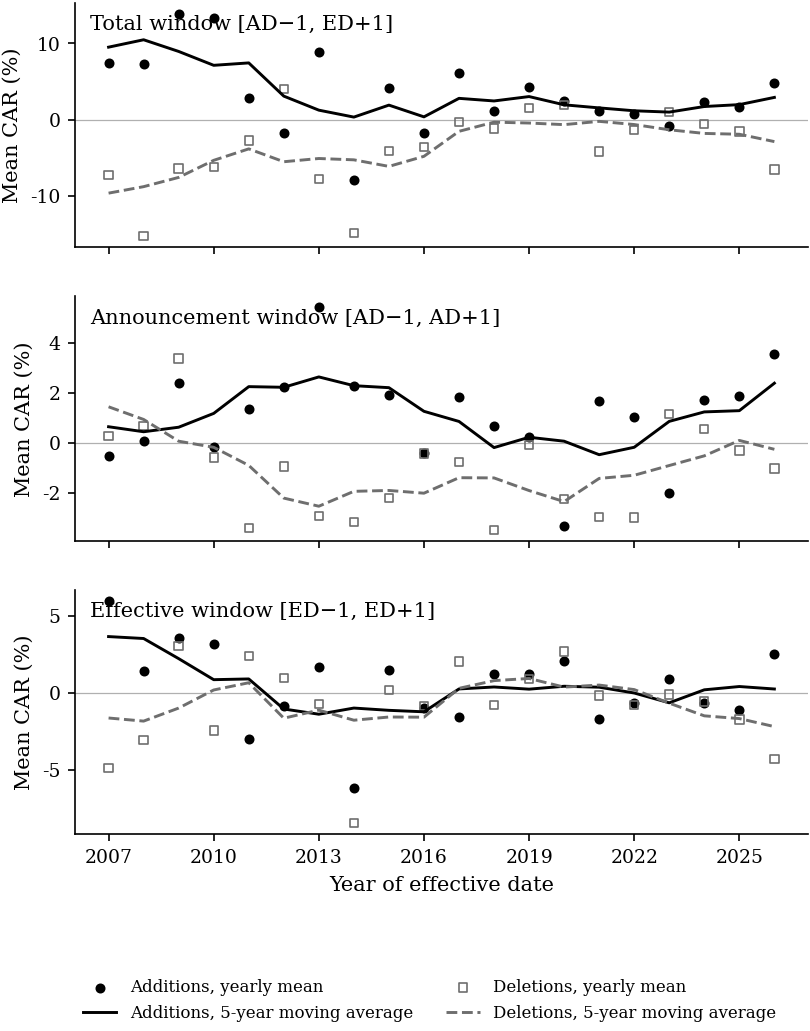

Additions                                Deletions                               
                  N       Ann       Eff      Total         N       Ann       Eff      Total
Year                                                                                       
2007              2 -0.532954  5.989125   7.389306         6  0.279513 -4.869487  -7.215971
2008              6  0.068958  1.459352   7.272474         5  0.688866 -3.039731 -15.284643
2009              9  2.411524  3.573563  13.869499        10  3.374048  3.068173  -6.390284
2010              5 -0.150968  3.173087  13.391707         7 -0.578681 -2.418611  -6.227271
2011             11  1.354034 -2.984861   2.823362        10 -3.409171  2.417160  -2.715515
2012             12  2.231432 -0.843656  -1.703953        20 -0.941439  1.005178   3.983929
2013              8  5.422688  1.697278   8.848764         6 -2.926595 -0.688344  -7.776808
2014              7  2.281296 -6.183193  -7.905169         6 -3.171434 -8.450023 -14.823972
2015             11  1.922685  1.475635   4.190908        10 -2.204264  0.199934  -4.104639
2016             16 -0.397891 -0.984156  -1.726081         5 -0.427506 -0.850507  -3.590257
2017             15  1.831841 -1.580450   6.147791         9 -0.769382  2.046441  -0.319410
2018             15  0.694950  1.219111   1.157364        11 -3.472670 -0.748844  -1.167061
2019             10  0.254531  1.236822   4.227905        14 -0.071734  0.917252   1.558013
2020             25 -3.307113  2.112508   2.478283        13 -2.251083  2.707235   1.895084
2021             17  1.667772 -1.688612   1.157560        16 -2.953120 -0.152506  -4.155219
2022             29  1.044057 -0.638448   0.737274        21 -2.984611 -0.759965  -1.367603
2023             13 -2.004516  0.913067  -0.865067        17  1.169095 -0.085674   0.982563
2024             17  1.738321 -0.646254   2.339637        15  0.561092 -0.548684  -0.525158
2025             17  1.875609 -1.074956   1.609721        12 -0.303329 -1.706893  -1.537645
2026             11  3.560565  2.530987   4.820021        12 -1.018162 -4.261288  -6.551490
All years       256  0.873560  0.093829   2.572383       225 -1.129364 -0.379244  -2.320010

In [12]:
by = ev.assign(year=ev.ED.dt.year).groupby(["type", "year"]).agg(N=("tot", "count"), ann=("ann", "mean"), eff=("eff", "mean"), tot=("tot", "mean"))
allr = ev.groupby("type").agg(N=("tot", "count"), ann=("ann", "mean"), eff=("eff", "mean"), tot=("tot", "mean"))
allr.index = pd.MultiIndex.from_tuples([(t, "All years") for t in allr.index])
by = pd.concat([by, allr])
t0 = by.unstack(0)
t0.columns = pd.MultiIndex.from_tuples([(LABELS[b], {"N": "N", "ann": "Ann", "eff": "Eff", "tot": "Total"}[a]) for a, b in t0.columns])
t0 = t0[[(LABELS[t], c) for t in ["addition", "deletion"] for c in ["N", "Ann", "Eff", "Total"]]]
t0 = t0.reindex([y for y in t0.index if y != "All years"] + ["All years"])
t0.index.name = "Year"
t0.to_csv(os.path.join(TAB, "tab_00_by_year.csv"))
t0b = t0.copy()
for c in t0b.columns:
    t0b[c] = t0b[c].map(lambda x: ("" if pd.isna(x) else (str(int(x)) if c[1] == "N" else f"{x:.2f}")))
tab_save(mt.MTable(t0b, notes="Number of events in the sample and mean cumulative abnormal return in percent against OMXSBGI over the announcement window [AD−1, AD+1], the effective-date window [ED−1, ED+1] and the total window [AD−1, ED+1], by year of the effective date (anchor Table 1)."), "tab_00_by_year", "Event counts and mean CARs by year of the effective date (anchor Table 1)")
f2 = ev.assign(year=ev.ED.dt.year).groupby(["type", "year"])[["tot", "ann", "eff"]].mean()
fig, axs = plt.subplots(3, 1, figsize=(6.3, 7.2), sharex=True)
f2d = {}
for ax, (w, lab) in zip(axs, [("tot", "Total window [AD−1, ED+1]"), ("ann", "Announcement window [AD−1, AD+1]"), ("eff", "Effective window [ED−1, ED+1]")]):
    for typ, mk, col in [("addition", "o", PALETTE[0]), ("deletion", "s", PALETTE[1])]:
        s = f2.loc[typ, w]
        ma = s.rolling(5, center=True, min_periods=1).mean()
        ax.scatter(s.index, s.values, s=16, marker=mk, facecolors=col if typ == "addition" else "none", edgecolors=col, linewidths=0.8, label=f"{LABELS[typ]}, yearly mean")
        ax.plot(ma.index, ma.values, color=col, linestyle="-" if typ == "addition" else "--", label=f"{LABELS[typ]}, 5-year moving average")
        f2d[(w, typ, "mean")] = s
        f2d[(w, typ, "ma5")] = ma
    ax.axhline(0, color=PALETTE[2], linewidth=0.6, zorder=0)
    ax.text(0.02, 0.95, lab, transform=ax.transAxes, va="top", ha="left")
    ax.set_ylabel("Mean CAR (%)")
axs[-1].set_xlabel("Year of effective date")
axs[-1].xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, fontsize=8)
fig_save(fig, "fig_02_by_year", "Mean CAR by year of the effective date with a centred five-year moving average, total, announcement and effective windows (anchor Figure 2)")
pd.DataFrame(f2d).round(3).to_csv(os.path.join(FIG, "fig_02_by_year.csv"))
t0

Sample sensitivity and selection

In [13]:
def hc1(y):
    y = np.asarray(y, float)
    y = y[np.isfinite(y)]
    n = len(y)
    return (np.nan, np.nan, n) if n < 2 else (y.mean(), y.std(ddof=1) / np.sqrt(n), n)
rows = []
for lab, d in [("No filter", ev_all), ("Listing/delisting filter", ev)]:
    for typ in ["addition", "deletion"]:
        s = d[d.type == typ]
        for p in PER + ["All"]:
            m, se, N = hc1(s.tot[s.period == p] if p != "All" else s.tot)
            rows.append(dict(sample=lab, type=typ, period=p, mean=m, se_hc1=se, N=N))
ta8 = pd.DataFrame(rows)
ta8.to_csv(os.path.join(TAB, "tabA_08_sample_sensitivity_long.csv"), index=False)
ta8["c"] = [f"{m:.2f}{star(2 * stats.norm.sf(abs(m / se)))}\n({se:.2f})\n[{N}]" if np.isfinite(se) else "" for m, se, N in zip(ta8["mean"], ta8.se_hc1, ta8.N)]
ta8w = ta8.pivot(index=["type", "period"], columns="sample", values="c").reindex(index=pd.MultiIndex.from_product([["addition", "deletion"], PER + ["All"]]), columns=["No filter", "Listing/delisting filter"])
ta8w.index = pd.MultiIndex.from_tuples([({"addition": "Panel A: Additions", "deletion": "Panel B: Deletions"}[a], b) for a, b in ta8w.index])
tab_save(mt.MTable(ta8w, rgroup_sep="t", notes="Mean cumulative abnormal return over the total window [AD−1, ED+1] in percent, HC1 standard errors in parentheses and the number of events in brackets, on all events with price data and on the main sample that drops events where the stock was listed within 100 days before or delisted within 100 days after the effective date. The anchor paper also drops acquirers within 100 days of the change; no acquirer flag is available here. Stars from the HC1 p-value: " + STARS), "tabA_08_sample_sensitivity", "Total-window CAR with and without the listing/delisting filter (anchor Table A2 analogue)", ta8.drop(columns="c").round(4))
lst = pd.concat([ev_all[["event_id", "effective_date", "type"]], nocov[["event_id", "effective_date", "type"]]])
ta9 = pd.DataFrame({"Events in list": lst.groupby(lst.effective_date.dt.year).size(), "With price data": ev_all.groupby(ev_all.effective_date.dt.year).size(), "In sample": ev.groupby(ev.effective_date.dt.year).size()}).fillna(0).astype(int)
ta9.loc["All years"] = ta9.sum()
ta9["Included (%)"] = (100 * ta9["In sample"] / ta9["Events in list"]).round(1)
ta9.index.name = "Year"
tab_save(mt.MTable(ta9.astype(str), notes="Events in the OMXSB change list by year of the effective date, events whose stock has price data in the LSEG panel around the change, events in the main sample after the listing/delisting filter, and the share of listed events that enter the sample (anchor Table A1 analogue)."), "tabA_09_sample_selection", "Sample selection by year (anchor Table A1 analogue)", ta9)
ta9

,Events in list,With price data,In sample,Included (%)
Year,,,,
2007,13,9,9,69.2
2008,18,14,13,72.2
2009,29,22,19,65.5
2010,17,13,13,76.5
2011,25,21,21,84.0
2012,40,32,32,80.0
2013,14,14,14,100.0
2014,14,14,13,92.9
2015,21,21,21,100.0


Phase 1 versus G&S convention

In [14]:
ph1 = pd.read_csv(PHASE1)
keep = PER + ["diff"]
pc = ph1[ph1.period.isin(keep)].merge(t2[t2.period.isin(keep)], on=["type", "window", "period"], suffixes=("_phase1", "_gs"), how="outer")
pc["d_mean"] = pc.mean_gs - pc.mean_phase1
pc["d_N"] = pc.N_gs - pc.N_phase1
pc = pc[["type", "window", "period", "mean_phase1", "mean_gs", "d_mean", "se_hc1_phase1", "se_hc1_gs", "N_phase1", "N_gs", "d_N"]]
pc.to_csv(os.path.join(OUT, "table2_phase1_vs_gs.csv"), index=False)
f3 = lambda c, v: (f"{v:.3f}" if isinstance(v, float) and not float(v).is_integer() else (str(int(v)) if isinstance(v, (float, int, np.integer)) else str(v)))
lines = ["# Table 2: phase 1 (missing days filled with a zero return) versus the Greenwood–Sammon convention (missing days kept as NaN, event dropped from the window)", "",
    "Both columns are from code/notebooks/replication_omxsb_2007.ipynb on data/raw/lseg/panel_2005_2026: phase 1 is the committed first run (tab_02_car_long_phase1.csv), G&S is the current run. Means are CARs in percent against .OMXSBGI; diff is the last period minus the second-to-last. Besides the missing-day rule the two runs differ only in exhibits that do not enter Table 2 (Table 3 controls, Figure 8 normalisation, new tables).", "",
    md_table(pc, f3), "",
    "## 2013–2026 against the original run (2012 panel, zero-filled), G&S convention", "",
    "The original run filled missing stock-days with a zero return; under the G&S convention the two events whose window contains a stock-day missing in the 2005 pull (OMXSB-2018H1-07 Africa Oil, OMXSB-2018H2-10 Veoneer) drop out of the affected windows instead of entering with a zero return, so their cells now differ in N as well as in the mean. Every other cell should match.", "",
    md_table(cmp, f3), ""]
with open(os.path.join(OUT, "table2_phase1_vs_gs.md"), "w") as f:
    f.write("\n".join(lines))
print(f"{int((pc.d_mean.abs() > 0.01).sum())} of {len(pc)} Table 2 cells differ by more than 0.01 pp between the phase-1 and the G&S convention; {int((pc.d_N != 0).sum())} differ in N")
print(pc.to_string(index=False))

6 of 36 Table 2 cells differ by more than 0.01 pp between the phase-1 and the G&S convention; 6 differ in N
    type window    period  mean_phase1   mean_gs        d_mean  se_hc1_phase1  se_hc1_gs  N_phase1  N_gs  d_N
addition    ann 2007–2012     1.324227  1.278194 -4.603342e-02       0.517017   0.525807        49    48   -1
addition    ann 2013–2017     1.782657  1.782657  0.000000e+00       0.640621   0.640621        57    57    0
addition    ann 2018–2020    -1.353202 -1.353202  0.000000e+00       0.887200   0.887200        51    51    0
addition    ann 2021–2023     0.552052  0.552052  0.000000e+00       0.855900   0.855900        59    59    0
addition    ann 2024–2026     2.235623  2.235623  0.000000e+00       1.088605   1.088605        45    45    0
addition    ann      diff     1.683571  1.683571  0.000000e+00       1.384094   1.384094       104   104    0
addition    eff 2007–2012     0.659897  0.647595 -1.230251e-02       0.679334   0.701700        49    47   -2
addition    

Table 3

In [15]:
px["ym"] = px.date.dt.to_period("M")
px["dturn"] = (px.volume / px.shares).where(px.shares > 0)
mon = px.groupby(["ric", "ym"]).agg(turn=("dturn", "mean"), mc=("mcap", "last")).reset_index()
mon = mon[np.isfinite(mon.turn)]
mk = mon.dropna(subset=["mc"]).groupby("ym").apply(lambda g: np.average(g.turn, weights=g.mc)).rename("mturn")
mon = mon.merge(mk, on="ym")
mon["xturn"] = mon.turn - mon.mturn
ev["ym_pre"] = (ev.AD - pd.offsets.MonthBegin(1)).dt.to_period("M")
ev = ev.merge(mon[["ric", "ym", "xturn"]].rename(columns={"ric": "RIC", "ym": "ym_pre", "xturn": "turn"}), on=["RIC", "ym_pre"], how="left")
mc = px.pivot(index="date", columns="ric", values="mcap").reindex(cal)
top100 = mc.apply(lambda r: r.nlargest(100).sum(), axis=1)
ev["mcap_pre"] = [mc.at[cal[i - 1], r] for r, i in zip(ev.RIC, ev.iAD)]
ev["size"] = ev.mcap_pre / top100.reindex(cal[ev.iAD - 1]).values * 100
sq = (AR ** 2)
sqm = sq.groupby(sq.index.to_period("M")).sum(min_count=1)
def vol12(ric, ym):
    s = sqm.loc[ym - 12:ym - 1, ric]
    return np.nan if s.isna().any() or len(s) < 12 else s.mean()
ev["vol"] = [vol12(r, y) for r, y in zip(ev.RIC, ev.ym_pre)]
ev[["turn", "size", "vol"]].describe().T

,count,mean,std,min,25%,50%,75%,max
turn,467.0,-0.130445,1.017660,-7.837825,-0.000857,0.000748,0.002853,0.509986
size,479.0,0.187210,0.332473,0.004509,0.041844,0.080510,0.179263,2.826897
vol,459.0,128.400116,188.271667,8.823951,54.963103,83.581648,134.048166,2741.884546


In [16]:
def reg3(s, ctrl):
    s = s.dropna(subset=["tot"] + (["turn", "size", "vol"] if ctrl else [])).copy()
    s["car"] = s.tot
    X = pd.concat(([s[["turn", "size", "vol"]]] if ctrl else []) + [pd.get_dummies(s.period).reindex(columns=PER).astype(float)], axis=1)
    m = sm.OLS(s.car, X).fit(cov_type="HC1")
    b, e, Vh, Vc, G, gs, _ = ols(s.car.values.astype(float), X.values.astype(float), s.adx.values)
    return m, list(np.sqrt(np.diag(Vc))), G
M, CR, GS = [], [], []
for typ in ["addition", "deletion"]:
    for ctrl in [False, True]:
        m, cr, G = reg3(ev[ev.type == typ], ctrl)
        M.append(m)
        CR.append(cr)
        GS.append(G)
t3 = pd.concat([pd.DataFrame({"model": i + 1, "var": m.params.index, "coef": m.params.values, "se_hc1": m.bse.values, "p_hc1": m.pvalues.values, "se_cr1": CR[i], "N": int(m.nobs), "G": GS[i], "r2": m.rsquared}) for i, m in enumerate(M)])
t3.to_csv(os.path.join(TAB, "tab_03_determinants_long.csv"), index=False)
NUM["t3_N_additions"] = int(M[1].nobs)
NUM["t3_N_deletions"] = int(M[3].nobs)
tab_save(mt.ETable(M, coef_fmt="b:.3f* \n (se:.3f) \n [cr1:.3f]", custom_stats={"cr1": CR}, custom_model_stats={"Controls": ["No", "Yes", "No", "Yes"], "Clusters": GS}, model_stats=["N", "r2"], model_stats_labels={"N": "Observations", "r2": "R$^2$"}, labels=LABELS, order=["turn", "size", "vol"] + PER, model_heads=[LABELS["addition"], LABELS["addition"], LABELS["deletion"], LABELS["deletion"]], show_fe=False, notes="OLS of the cumulative abnormal return from AD−1 to ED+1 in percent on period dummies without a constant; columns (1) and (3) give the raw period means of Table 2 on the full sample, columns (2) and (4) add the controls of equation (4) on the events with non-missing controls. Excess turnover is the average daily turnover (volume over shares outstanding) in the calendar month before AD minus the market-cap-weighted average of the same quantity across all .ST stocks in the panel in that month; size is market cap on AD−1 over the summed market cap of the 100 largest .ST stocks that day, an approximation of total OMXSB market capitalisation; volatility is the 12-month moving average of the monthly sum of squared daily market-adjusted returns. The controls enter uncentred as in equation (4) of the anchor paper, so in columns (2) and (4) each period coefficient is the expected CAR at zero excess turnover, zero size and zero volatility. HC1 standard errors in parentheses and standard errors clustered on announcement date in brackets; stars use HC1 p-values: " + STARS), "tab_03_determinants", "Determinants of the index effect with period dummies (anchor Table 3)")

CAR, AD−1 to ED+1 (%) 
 
 
 
 
 
 Additions 
 
 
 Deletions 
 
 
 
 (1) 
 (2) 
 (3) 
 (4) 
 
 
 
 
 coef 
 
 
 Excess turnover (monthly volume / shares) 
 
 -0.501** (0.245) [0.355] 
 
 0.259 (0.573) [0.388] 
 
 
 Size (% of top-100 market cap) 
 
 -0.016 (1.810) [1.474] 
 
 0.028 (0.805) [0.893] 
 
 
 Volatility (sum of squared daily AR, %) 
 
 0.008 (0.009) [0.008] 
 
 -0.010* (0.006) [0.006] 
 
 
 2007–2012 
 5.796*** (1.350) [2.458] 
 5.222*** (1.878) [2.706] 
 -3.012** (1.353) [2.788] 
 -1.198 (1.741) [3.476] 
 
 
 2013–2017 
 2.213 (1.431) [1.893] 
 1.969 (1.966) [2.200] 
 -5.485*** (1.790) [2.120] 
 -5.446*** (1.920) [2.469] 
 
 
 2018–2020 
 2.432 (1.589) [0.784] 
 0.775 (2.196) [1.458] 
 0.884 (1.535) [1.640] 
 1.808 (1.638) [1.741] 
 
 
 2021–2023 
 0.505 (1.012) [0.662] 
 -0.920 (2.033) [1.354] 
 -1.454* (0.808) [1.274] 
 0.600 (1.163) [1.359] 
 
 
 2024–2026 
 2.670 (1.875) [0.622] 
 1.589 (1.303) [1.092] 
 -2.691*** (0.903) [1.491] 
 -1.633 (1.056) [1.555] 
 
 
 stats 
 
 
 Controls 
 No 
 Yes 
 No 
 Yes 
 
 
 Clusters 
 38 
 38 
 38 
 38 
 
 
 Observations 
 256 
 229 
 225 
 208 
 
 
 R$^2$ 
 0.026 
 0.064 
 0.048 
 0.079 
 
 
 OLS of the cumulative abnormal return from AD−1 to ED+1 in percent on period dummies without a constant; columns (1) and (3) give the raw period means of Table 2 on the full sample, columns (2) and (4) add the controls of equation (4) on the events with non-missing controls. Excess turnover is the average daily turnover (volume over shares outstanding) in the calendar month before AD minus the market-cap-weighted average of the same quantity across all .ST stocks in the panel in that month; size is market cap on AD−1 over the summed market cap of the 100 largest .ST stocks that day, an approximation of total OMXSB market capitalisation; volatility is the 12-month moving average of the monthly sum of squared daily market-adjusted returns. The controls enter uncentred as in equation (4) of the anchor paper, so in columns (2) and (4) each period coefficient is the expected CAR at zero excess turnover, zero size and zero volatility. HC1 standard errors in parentheses and standard errors clustered on announcement date in brackets; stars use HC1 p-values: * p<0.10, ** p<0.05, *** p<0.01.

Fund holdings

In [17]:
BAD = re.compile("[^\x09\x0a\x0d\x20-\ud7ff\ue000-\ufffd]")
FUND = ["Kvartalsslut", "Fondbolag_namn", "Fond_institutnummer", "Fond_namn", "Fond_ISIN-kod", "Fondförmögenhet"]
INS = ["Tillgångsslag_enligt_LVF_5_kap", "Instrumentnamn", "ISIN-kod_instrument", "Landkod_Emittent", "Valuta", "Antal", "Kurs_som_använts_vid_värdering_av_instrumentet", "Marknadsvärde_instrument", "Andel_av_fondförmögenhet_instrument"]
NUMC = ["Antal", "Kurs_som_använts_vid_värdering_av_instrumentet", "Marknadsvärde_instrument", "Andel_av_fondförmögenhet_instrument", "Fondförmögenhet"]
FIL = os.path.join(DER, "fi_holdings_long.csv.gz")
def rd(p):
    b = open(p, "rb").read()
    try:
        t = b.decode("utf-8-sig")
    except UnicodeDecodeError:
        t = b.decode("latin-1")
    t = re.sub(r'\sxmlns="[^"]+"', "", BAD.sub("", t), count=1)
    return ET.fromstring(t)
def tx(e, tag):
    x = e.find(".//" + tag)
    return None if x is None or x.text is None else x.text.strip()
def parse(p):
    r = rd(p)
    f = {k: tx(r, k) for k in FUND}
    f["Jämförelseindex"] = " | ".join(x.text.strip() for x in r.iter("Jämförelseindex") if x.text and x.text.strip())
    m = re.search(r"_VPFO_(\d{4}Q\d)_(\d{4}-\d{2}-\d{2} \d{2}\.\d{2})\.xml$", os.path.basename(p))
    f["pub"] = m.group(2) if m else None
    rows = []
    for ins in r.iter("FinansielltInstrument"):
        d = {k: tx(ins, k) for k in INS}
        d.update(f)
        rows.append(d)
    return rows
LOADED = os.path.exists(FIL)
parts, bad = [], []
if LOADED:
    h = pd.read_csv(FIL, dtype=str, compression="gzip")
    print(f"{os.path.basename(FIL)} loaded from data/derived/fi ({len(h):,} rows); the FI zips are not re-parsed and the file is not rewritten")
else:
    for zp in ZIPS:
        with tempfile.TemporaryDirectory() as td:
            with zipfile.ZipFile(zp) as z:
                z.extractall(td)
            files = [os.path.join(dp, fn) for dp, _, fns in os.walk(td) for fn in fns if fn.lower().endswith(".xml")]
            rows = []
            for p in files:
                try:
                    rows.extend(parse(p))
                except ET.ParseError as e:
                    bad.append((os.path.basename(zp), os.path.basename(p), str(e)))
            df = pd.DataFrame(rows)
            df["zip"] = os.path.basename(zp)
            df["n_files"] = len(files)
            parts.append(df)
    h = pd.concat(parts, ignore_index=True)
for c in NUMC:
    h[c] = pd.to_numeric(h[c], errors="coerce")
h["Kvartalsslut"] = pd.to_datetime(h.Kvartalsslut)
pd.DataFrame(bad, columns=["zip", "file", "error"])

fi_holdings_long.csv.gz loaded from data/derived/fi (3,064,860 rows); the FI zips are not re-parsed and the file is not rewritten


,zip,file,error


In [18]:
h0 = len(h)
if LOADED:
    dups = pd.DataFrame(columns=["Fond_institutnummer", "Fond_namn", "Kvartalsslut", "pub"])
    print("duplicate fund-quarter files were removed when the loaded file was built, so none are listed here")
else:
    last = h.groupby(["Fond_institutnummer", "Kvartalsslut"]).pub.transform("max")
    dups = h[last != h.pub].drop_duplicates(["Fond_institutnummer", "Kvartalsslut", "pub"])[["Fond_institutnummer", "Fond_namn", "Kvartalsslut", "pub"]]
    h = h[last == h.pub].drop(columns=["pub", "n_files"]).reset_index(drop=True)
    h.to_csv(FIL, index=False, compression="gzip")
display(dups)
pd.DataFrame({"rows_raw": [h0], "rows": [len(h)], "funds": [h.Fond_institutnummer.nunique()], "quarters": [h.Kvartalsslut.nunique()]})

duplicate fund-quarter files were removed when the loaded file was built, so none are listed here


,Fond_institutnummer,Fond_namn,Kvartalsslut,pub


,rows_raw,rows,funds,quarters
0,3064860,3064860,886,31


In [19]:
h.groupby("Kvartalsslut").agg(funds=("Fond_institutnummer", "nunique"), rows=("Antal", "size"), zip=("zip", "first"))

,funds,rows,zip
Kvartalsslut,,,
2018-12-31,571,85624,Fondinnehav_2018Q4_2022-11-16 17.05.zip
2019-03-31,562,84708,Fondinnehav_2019Q1_2022-11-16 17.35.zip
2019-06-30,551,84122,Fondinnehav_2019Q2_2022-11-16 15.35.zip
2019-09-30,556,86437,Fondinnehav_2019Q3_2022-11-11 15.05.zip
2019-12-31,556,85220,Fondinnehav_2019Q4_2022-10-28 14.04.zip
2020-03-31,559,88002,Fondinnehav_2020Q1_2022-10-28 14.34.zip
2020-06-30,572,88458,Fondinnehav_2020Q2_2022-10-28 14.34.zip
2020-09-30,579,88528,Fondinnehav_2020Q3_2022-10-31 15.06.zip
2020-12-31,586,89215,Fondinnehav_2020Q4_2022-10-28 14.34.zip


Event ISINs

In [20]:
STOP = {"AB", "PUBL", "SER", "SERIE", "SERIES", "SHS", "SHARE", "SHARES", "ORD", "CLASS", "CL", "AKTIEBOLAG", "THE", "INC", "CORP", "CORPORATION", "LTD", "PLC", "OYJ", "ASA", "SA", "SDB", "SDR", "REG", "REGISTERED", "NPV", "STK", "AKTIE", "AKTIER", "ORDINARY", "COMMON", "STOCK", "VPL"}
def norm(s):
    s = re.sub(r"\([^)]*\)", " ", str(s).upper().replace("&", " "))
    t = re.sub(r"[^A-Z0-9 ]", " ", s).split()
    return " ".join(x for x in t if x not in STOP)
eq = h[(h.Tillgångsslag_enligt_LVF_5_kap == "ÖverlåtbartVärdepapper") & h.Antal.notna() & (h.Antal > 0) & h["ISIN-kod_instrument"].notna()].copy()
eq["nname"] = eq.Instrumentnamn.map(norm)
Q = pd.DatetimeIndex(sorted(h.Kvartalsslut.unique()))
e5 = ev[ev.AD > Q.min()].copy()
e5["qb"] = [Q[Q < d].max() for d in e5.AD]
e5["qa"] = [Q[Q > d].min() for d in e5.ED]
e5["isin0"] = e5["isin"].where(e5["isin"].notna(), e5.IssueISIN)
qi = eq.groupby("Kvartalsslut")["ISIN-kod_instrument"].agg(set)
nm_isin = eq.groupby("nname")["ISIN-kod_instrument"].agg(set)
isin_nm = eq.groupby("ISIN-kod_instrument").nname.agg(set)
cnt = eq.groupby(["nname", "ISIN-kod_instrument"]).size()
dom = eq.groupby("ISIN-kod_instrument").nname.agg(lambda x: x.value_counts().index[0])
known = set(e5.isin0.dropna())
rows, sets, flags = [], [], []
for _, r in e5.iterrows():
    s = set() if pd.isna(r.isin0) else {r.isin0}
    inb = bool(s) and r.isin0 in qi[r.qb]
    ina = bool(s) and r.isin0 in qi[r.qa]
    names = (isin_nm.get(r.isin0, set()) if s else set()) | {norm(r.company)}
    pre = r.isin0[:2] if s else None
    for nn in sorted(names):
        for i in sorted(nm_isin.get(nn, set())):
            if i not in s and i not in known and (pre is None or i[:2] == pre) and (dom[i] in names or (pre is None and nn == norm(r.company))):
                s.add(i)
                rows.append(dict(event_id=r.event_id, company=r.company, isin0=r.isin0, in_q_before=inb, in_q_after=ina, nname=nn, isin_match=i, dominant_name=dom[i], n_rows=int(cnt[(nn, i)])))
    sets.append(s)
    flags.append((inb, ina))
e5["isins"] = sets
e5["isin0_in_qb"] = [f[0] for f in flags]
e5["isin0_in_qa"] = [f[1] for f in flags]
nmatch = pd.DataFrame(rows)
nm_tab = nmatch.rename(columns={"event_id": "Event", "company": "Company", "isin0": "LSEG ISIN", "nname": "Matched name", "isin_match": "Added ISIN", "dominant_name": "Dominant name of added ISIN", "n_rows": "Rows"})[["Event", "Company", "LSEG ISIN", "Matched name", "Added ISIN", "Dominant name of added ISIN", "Rows"]].set_index("Event")
tab_save(mt.MTable(nm_tab, notes="ISINs added to an event beyond the LSEG issue ISIN because the dominant normalised instrument name of the added ISIN in the FI holdings data equals a name reported for the LSEG ISIN or the normalised company name. Rows is the number of fund-quarter holdings rows carrying the added ISIN under the matched name."), "tabA_02_isin_matches", "ISIN name matches used to bridge ISIN changes in FI holdings", nm_tab)

,Company,LSEG ISIN,Matched name,Added ISIN,Dominant name of added ISIN,Rows
OMXSB-2019H1-06,Nyfosa AB,None,NYFOSA,SE0011426428,NYFOSA,1883
OMXSB-2019H1-07,Atrium Ljungberg AB ser. B,SE0024320832,ATRIUM LJUNGBERG,SE0000191827,ATRIUM LJUNGBERG B,561
OMXSB-2019H1-11,Karo Pharma AB,SE0007464888,KARO BIO,SE0017767148,KARO BIO,3
OMXSB-2019H1-14,Tethys Oil AB,SE0020180917,TETHYS OIL,SE0011115971,TETHYS OIL,40
OMXSB-2019H1-14,Tethys Oil AB,SE0020180917,TETHYS OIL,SE0012455202,TETHYS OIL,40
OMXSB-2019H1-14,Tethys Oil AB,SE0020180917,TETHYS OIL,SE0014399424,TETHYS OIL,26
OMXSB-2019H1-14,Tethys Oil AB,SE0020180917,TETHYS OIL,SE0015949847,TETHYS OIL,22
OMXSB-2019H1-14,Tethys Oil AB,SE0020180917,TETHYS OIL,SE0017859259,TETHYS OIL,24
OMXSB-2019H2-01,Atrium Ljungberg AB ser. B,SE0024320832,ATRIUM LJUNGBERG,SE0000191827,ATRIUM LJUNGBERG B,561
OMXSB-2019H2-04,Fingerprint Cards AB ser. B,SE0026141665,FINGERPRINT CARDS,SE0008374250,FINGERPRINT CARDS B,160


In [21]:
e5["n_isin"] = e5.isins.map(len)
pd.DataFrame({"events_total": [len(ev)], "events_with_q_before": [len(e5)], "events_dropped_pre_2018Q4": [len(ev) - len(e5)], "no_isin_found": [int((e5.n_isin == 0).sum())], "isin0_missing_q_before": [int((~e5.isin0_in_qb).sum())], "isin0_missing_q_after": [int((~e5.isin0_in_qa).sum())], "events_with_name_matches": [nmatch.event_id.nunique() if len(nmatch) else 0]})

,events_total,events_with_q_before,events_dropped_pre_2018Q4,no_isin_found,isin0_missing_q_before,isin0_missing_q_after,events_with_name_matches
0,487,259,228,0,31,29,88


In [22]:
CLS = {"A", "B", "C", "D", "R"}
def core(s):
    return set(norm(s).split()) - CLS
def cls(s):
    t = norm(s).split()
    return t[-1] if t and t[-1] in CLS else None
nmc = nmatch.copy()
nmc["names_added"] = nmc.isin_match.map(lambda i: ";".join(sorted(isin_nm.get(i, set()))))
nmc["missing_tokens"] = [" ".join(sorted(core(c) - set(d.split()))) for c, d in zip(nmc.company, nmc.dominant_name)]
nmc["class_event"] = nmc.company.map(cls)
nmc["classes_added"] = nmc.names_added.map(lambda s: ";".join(sorted({c for c in (cls(x) for x in s.split(";")) if c})))
nmc["flag_name"] = nmc.missing_tokens != ""
nmc["flag_class"] = [bool(e) and bool(a) and any(c != e for c in a.split(";")) for e, a in zip(nmc.class_event, nmc.classes_added)]
nmchk = nmc.groupby(["event_id", "company", "isin0"], dropna=False).agg(added_isins=("isin_match", ";".join), dominant_names=("dominant_name", lambda x: ";".join(sorted(set(x)))), all_names_added=("names_added", lambda x: ";".join(sorted(set(";".join(x).split(";"))))), rows=("n_rows", "sum"), missing_tokens=("missing_tokens", lambda x: ";".join(sorted(set(x) - {""}))), classes_added=("classes_added", lambda x: ";".join(sorted(set(";".join(x).split(";")) - {""}))), flag_name=("flag_name", "any"), flag_class=("flag_class", "any")).reset_index()
nmchk["flag"] = nmchk.flag_name | nmchk.flag_class
nmchk.to_csv(os.path.join(TAB, "tabA_02_isin_matches_check.csv"), index=False)
print(f"{len(nmchk)} events matched by name; {int(nmchk.flag_name.sum())} flagged because the FI name lacks a token of the event company name, {int(nmchk.flag_class.sum())} flagged because a name reported for an added ISIN carries another share class")
print(nmchk[nmchk.flag][["event_id", "company", "isin0", "added_isins", "dominant_names", "all_names_added", "missing_tokens", "classes_added", "flag_name", "flag_class"]].to_string())
nmchk[["event_id", "company", "isin0", "added_isins", "dominant_names", "rows", "flag"]]


88 events matched by name; 5 flagged because the FI name lacks a token of the event company name, 6 flagged because a name reported for an added ISIN carries another share class
           event_id                    company         isin0                             added_isins   dominant_names                                                                                                                                                                                                                                                                          all_names_added missing_tokens classes_added  flag_name  flag_class
2   OMXSB-2019H1-11             Karo Pharma AB  SE0007464888                            SE0017767148         KARO BIO                                                                                                                                                                                                           KARO BIO;KARO BIO SUBS RIGHT APR22;KARO PHARMA RIGH

,event_id,company,isin0,added_isins,dominant_names,rows,flag
0,OMXSB-2019H1-06,Nyfosa AB,NaN,SE0011426428,NYFOSA,1883,False
1,OMXSB-2019H1-07,Atrium Ljungberg AB ser. B,SE0024320832,SE0000191827,ATRIUM LJUNGBERG B,561,False
2,OMXSB-2019H1-11,Karo Pharma AB,SE0007464888,SE0017767148,KARO BIO,3,True
3,OMXSB-2019H1-14,Tethys Oil AB,SE0020180917,SE0011115971;SE0012455202;SE0014399424;SE00159...,TETHYS OIL,152,False
4,OMXSB-2019H2-01,Atrium Ljungberg AB ser. B,SE0024320832,SE0000191827,ATRIUM LJUNGBERG B,561,False
5,OMXSB-2019H2-04,Fingerprint Cards AB ser. B,SE0026141665,SE0008374250;SE0022241162;SE0018768277;SE00235...,FINGERPRINT CARDS;FINGERPRINT CARDS B,215,False
6,OMXSB-2019H2-05,Loomis AB ser. B,SE0014504817,SE0002683557,LOOMIS B,54,False
7,OMXSB-2019H2-06,SWECO AB ser. B,SE0014960373,SE0000489098,SWECO B,31,False
8,OMXSB-2020H1-02,Lifco AB ser. B,SE0015949201,SE0006370730,LIFCO B,268,False
9,OMXSB-2020H1-07,Atrium Ljungberg AB ser. B,SE0024320832,SE0000191827,ATRIUM LJUNGBERG B,561,False


Index funds

In [23]:
alli = set().union(*e5.isins)
eqe = eq[eq["ISIN-kod_instrument"].isin(alli)].copy()
hold = eqe.groupby(["Kvartalsslut", "ISIN-kod_instrument", "Fond_institutnummer"]).Antal.sum()
pres = h.groupby("Kvartalsslut").Fond_institutnummer.agg(set)
funds = h.sort_values("Kvartalsslut").groupby("Fond_institutnummer").agg(Fondbolag_namn=("Fondbolag_namn", "last"), Fond_namn=("Fond_namn", "last"), Fond_ISIN=("Fond_ISIN-kod", "last"), benchmark=("Jämförelseindex", "last"), q_first=("Kvartalsslut", "min"), q_last=("Kvartalsslut", "max"))
def own(q, isins):
    parts = [hold.loc[(q, i)] for i in isins if (q, i) in hold.index.droplevel(2)]
    return pd.concat(parts).groupby(level=0).sum() if parts else pd.Series(dtype=float)
own_b = {r.event_id: own(r.qb, r.isins) for r in e5.itertuples()}
own_a = {r.event_id: own(r.qa, r.isins) for r in e5.itertuples()}
e5["year"] = e5.ED.dt.year
rec = []
for r in e5.itertuples():
    both = pres[r.qb] & pres[r.qa]
    ob, oa = own_b[r.event_id], own_a[r.event_id]
    for f in both:
        b, a = ob.get(f, 0.0) > 0, oa.get(f, 0.0) > 0
        hit = (not b and a) if r.type == "addition" else (b and not a)
        rec.append((f, r.year, hit))
fy = pd.DataFrame(rec, columns=["fund", "year", "hit"]).groupby(["fund", "year"]).hit.agg(["mean", "size"]).reset_index()
score = fy.groupby("fund").agg(score=("mean", "mean"), years=("year", "nunique"), events=("size", "sum"))
funds = funds.join(score)
funds["index_trade"] = funds.score >= 0.5
funds["index_name"] = funds.Fond_namn.str.contains(r"index|omx|zero", case=False, regex=True) | funds.benchmark.str.contains("OMX", case=False, regex=True)
idx = funds[funds.index_trade].sort_values("score", ascending=False)
idx.reset_index().to_csv(os.path.join(OUT, "index_funds.csv"), index=False)
NUM["n_index_funds"] = int(len(idx))
idx_tab = idx[["Fondbolag_namn", "Fond_namn", "score", "years", "events"]].rename(columns={"Fondbolag_namn": "Fund company", "Fond_namn": "Fund", "score": "Match share", "years": "Years", "events": "Events"}).set_index("Fund company")
idx_tab["Match share"] = idx_tab["Match share"].round(3)
tab_save(mt.MTable(idx_tab, notes="Funds classified as OMXSB index trackers following the anchor paper: for each fund and year, the share of OMXSB events in which the fund bought the added stock between the quarter before the announcement and the quarter after the effective date, or sold the deleted stock, among the events in which the fund reports in both quarters; a fund is a tracker if its mean share over years is at least 0.5. All listed funds also carry index, OMX or Zero in their name or an OMX index as benchmark."), "tabA_03_index_funds", "Funds classified as OMXSB index trackers from their trades", idx_tab)
idx[["Fondbolag_namn", "Fond_namn", "benchmark", "score", "years", "events", "index_name"]]

,Fondbolag_namn,Fond_namn,benchmark,score,years,events,index_name
Fond_institutnummer,,,,,,,
60293,Nordea Funds Ab,Nordea Sverige Passiv,OMX Stockholm Benchmark Cap 100;,0.967079,8.0,259.0,True
60320,Nordnet Fonder AB,Nordnet Sverige Index,OMXSBESGGI,0.957740,8.0,259.0,True
52163,Swedbank Robur Fonder AB,Swedbank Robur Access Mix,OMRX Bond All 50.00; OMX Stockholm Benchmark C...,0.815516,8.0,259.0,True
60824,Swedbank Robur Fonder AB,Swedbank Robur Access Sverige,OMX Stockholm Benchmark Cap Gross,0.727574,8.0,259.0,True
60967,Lannebo Kapitalförvaltning AB,Lannebo Marknad Sverige,OMX SBXCAP GI,0.646996,8.0,259.0,True
51437,Nordea Funds Ab,Institutionella Aktiefonden Sverige,OMX Stockholm Benchmark Cap ESG 100;,0.634294,8.0,259.0,True
60718,Nordea Funds Ab,Nordea Generationsfond 90-tal,MSCI World ex Sweden Net Return 59.9; OMX Stoc...,0.630648,8.0,259.0,True
51615,Nordea Funds Ab,Nordea Generationsfond 50-tal,OMRX Mortgage 3-5 44; OMRX Municipal 24; MSCI ...,0.630270,8.0,259.0,True
51617,Nordea Funds Ab,Nordea Generationsfond 60-tal,MSCI World High Dividend Yield (Local SEK) Net...,0.630270,8.0,259.0,True


In [24]:
funds[funds.index_name & ~funds.index_trade].sort_values("score", ascending=False)[["Fondbolag_namn", "Fond_namn", "benchmark", "score", "years", "events"]].head(40)

,Fondbolag_namn,Fond_namn,benchmark,score,years,events
Fond_institutnummer,,,,,,
51080,Swedbank Robur Fonder AB,Swedbank Robur Access Edge Sweden,OMX Stockholm Benchmark Cap Gross,0.350620,7.0,235.0
56020,Swedbank Robur Fonder AB,KPA Blandfond,MSCI World ex Sweden Net 33.00; OMX Stockholm ...,0.294731,8.0,259.0
51482,Storebrand Asset Management AS,Storebrand Sverige,OMX Stockholm Benchmark Cap Gross Index,0.231889,8.0,259.0
60479,Handelsbanken Fonder AB,Handelsbanken Sverige 100 Index Criteria,Solactive ISS ESG Screened Sweden 100 Tradable...,0.186135,8.0,259.0
56084,Nordea Funds Ab,Nordea Stratega 50,MSCI World Net Return 42.5; OMRX T-Bond 32.5; ...,0.139275,8.0,259.0
52346,Nordea Funds Ab,Nordea Stratega 15,OMRX T-Bond 51.5; OMRX T-Bill 20; HFRX Global ...,0.131462,8.0,259.0
60003,Nordea Funds Ab,Nordea Stratega 35,OMRX T-Bond 45; MSCI World Net Return 29.8; OM...,0.123650,8.0,259.0
51783,Nordea Funds Ab,Nordea Stratega 70,MSCI World Net Return 59.5; OMRX T-Bond 23.5; ...,0.123650,8.0,259.0
50767,Cicero Fonder AB,Cicero Sverige,OMXS30,0.119074,8.0,246.0


In [25]:
pd.crosstab(funds.index_trade, funds.index_name, margins=True)

index_name,False,True,All
index_trade,,,
False,747,125,872
True,0,14,14
All,747,139,886


Net trading

In [26]:
IDX = set(funds.index[funds.index_trade])
nonidx = set(funds.index) - IDX
shw = px.pivot(index="date", columns="ric", values="shares").reindex(cal).ffill()
mcw = px.pivot(index="date", columns="ric", values="mcap").reindex(cal).ffill()
clw = px.pivot(index="date", columns="ric", values="close").reindex(cal).ffill()
def last_at(W, ric, q):
    s = W[ric].loc[:q].dropna()
    return s.iloc[-1] if len(s) else np.nan
def fi_price(q, isins):
    s = eqe[(eqe.Kvartalsslut == q) & eqe["ISIN-kod_instrument"].isin(isins) & (eqe.Valuta == "SEK")]
    return (s.Marknadsvärde_instrument / s.Antal).median() if len(s) else np.nan, s.Kurs_som_använts_vid_värdering_av_instrumentet.median() if len(s) else np.nan, len(s)
RAT = np.array([n for n in range(2, 51)] + [1 / n for n in range(2, 51)], float)
def snap(f):
    if not np.isfinite(f):
        return 1.0
    j = np.argmin(np.abs(f / RAT - 1))
    return RAT[j] if abs(f / RAT[j] - 1) < 0.03 else 1.0
chk = []
for r in e5.itertuples():
    pb, kb, nb = fi_price(r.qb, r.isins)
    pa, ka, na = fi_price(r.qa, r.isins)
    cb, ca = last_at(clw, r.RIC, r.qb), last_at(clw, r.RIC, r.qa)
    lb = last_at(mcw, r.RIC, r.qb) / last_at(shw, r.RIC, r.qb)
    la = last_at(mcw, r.RIC, r.qa) / last_at(shw, r.RIC, r.qa)
    f = (pb / pa) / (cb / ca)
    chk.append(dict(event_id=r.event_id, company=r.company, qb=r.qb, qa=r.qa, n_rows_b=nb, n_rows_a=na, fi_price_b=pb, fi_kurs_b=kb, lseg_price_b=lb, fi_price_a=pa, fi_kurs_a=ka, lseg_price_a=la, adj_close_b=cb, adj_close_a=ca, f_raw=f, f=snap(f)))
chk = pd.DataFrame(chk)
chk["kurs_vs_mv_b"] = chk.fi_kurs_b / chk.fi_price_b
chk["kurs_vs_mv_a"] = chk.fi_kurs_a / chk.fi_price_a
chk["fi_vs_lseg_b"] = chk.fi_price_b / chk.lseg_price_b
chk["fi_vs_lseg_a"] = chk.fi_price_a / chk.lseg_price_a
chk.to_csv(os.path.join(OUT, "holdings_price_check.csv"), index=False)
sf = chk[chk.f != 1][["event_id", "company", "qb", "qa", "fi_price_b", "fi_price_a", "adj_close_b", "adj_close_a", "f_raw", "f"]].rename(columns={"event_id": "Event", "company": "Company", "qb": "Quarter before", "qa": "Quarter after", "fi_price_b": "FI price before", "fi_price_a": "FI price after", "adj_close_b": "Adjusted close before", "adj_close_a": "Adjusted close after", "f_raw": "Raw factor", "f": "Factor used"}).set_index("Event")
for c in ["Quarter before", "Quarter after"]:
    sf[c] = sf[c].dt.strftime("%Y-%m-%d")
tab_save(mt.MTable(sf.round(3), notes="Events where the share count reported by funds in the quarter before the announcement is converted to the units of the quarter after the effective date. The raw factor is the ratio of the FI-reported price change to the LSEG split-adjusted close change between the two quarters; it is snapped to the nearest integer ratio within 3 percent, otherwise set to one. Fund-reported prices equal market value over quantity in every event quarter."), "tabA_04_split_factors", "Split factors applied to pre-announcement fund holdings", sf)
display(chk[["kurs_vs_mv_b", "kurs_vs_mv_a", "fi_vs_lseg_b", "fi_vs_lseg_a", "f_raw", "f"]].describe().T.round(3))
chk[chk.f != 1][["event_id", "company", "qb", "qa", "fi_price_b", "fi_price_a", "adj_close_b", "adj_close_a", "f_raw", "f"]]

,count,mean,std,min,25%,50%,75%,max
kurs_vs_mv_b,259.0,1.000,0.000,1.000,1.000,1.000,1.0,1.000
kurs_vs_mv_a,259.0,1.000,0.000,1.000,1.000,1.000,1.0,1.000
fi_vs_lseg_b,253.0,0.966,0.214,0.223,0.987,0.999,1.0,2.920
fi_vs_lseg_a,253.0,0.957,0.174,0.223,0.983,0.999,1.0,1.993
f_raw,259.0,1.026,0.233,0.992,1.000,1.000,1.0,4.000
f,259.0,1.023,0.232,1.000,1.000,1.000,1.0,4.000


,event_id,company,qb,qa,fi_price_b,fi_price_a,adj_close_b,adj_close_a,f_raw,f
44,OMXSB-2020H2-10,Lagercrantz Group,2020-09-30,2020-12-31,181.0,76.0,60.333273,76.0,3.000003,3.0
95,OMXSB-2022H1-01,Addnode Group AB ser. B,2022-03-31,2022-06-30,385.5,83.4,96.375000,83.4,4.000000,4.0
98,OMXSB-2022H1-04,Heba Fastighets AB ser. B,2022-03-31,2022-06-30,151.6,41.8,75.800000,41.8,2.000000,2.0


In [27]:
e5 = e5.merge(chk[["event_id", "f"]], on="event_id", how="left")
e5["shares_qa"] = [last_at(shw, r, q) for r, q in zip(e5.RIC, e5.qa)]
def agg(d, fs):
    return float(d.loc[d.index.isin(fs)].sum()) if fs is not None else float(d.sum())
e5["idx_b"] = [agg(own_b[i], IDX) * f for i, f in zip(e5.event_id, e5.f)]
e5["idx_a"] = [agg(own_a[i], IDX) for i in e5.event_id]
e5["all_b"] = [agg(own_b[i], None) * f for i, f in zip(e5.event_id, e5.f)]
e5["all_a"] = [agg(own_a[i], None) for i in e5.event_id]
e5["act_b"] = [agg(own_b[i], nonidx) * f for i, f in zip(e5.event_id, e5.f)]
e5["act_a"] = [agg(own_a[i], nonidx) for i in e5.event_id]
e5["nt"] = 100 * (e5.idx_a - e5.idx_b) / e5.shares_qa
e5["instbuy"] = 100 * (e5.all_a - e5.all_b) / e5.shares_qa
e5["activebuy"] = 100 * (e5.act_a - e5.act_b) / e5.shares_qa
e5["indexown"] = 100 * e5.idx_b / e5.shares_qa
e5["n_idx_funds_b"] = [int((own_b[i].loc[own_b[i].index.isin(IDX)] > 0).sum()) for i in e5.event_id]
e5["n_idx_funds_a"] = [int((own_a[i].loc[own_a[i].index.isin(IDX)] > 0).sum()) for i in e5.event_id]
e5.groupby(["period", "type"])[["nt", "instbuy", "activebuy", "indexown"]].describe().T.round(2)

period          2018–2020          2021–2023          2024–2026         
type             addition deletion  addition deletion  addition deletion
nt        count     34.00    26.00     58.00    52.00     45.00    38.00
          mean       1.10    -0.66      0.84    -0.90      1.22    -1.46
          std        0.46     0.46      0.49     0.47      0.64     0.78
          min        0.44    -1.68      0.00    -2.25      0.03    -3.34
          25%        0.72    -0.94      0.50    -1.20      0.82    -1.91
          50%        1.09    -0.59      0.81    -0.81      1.19    -1.53
          75%        1.32    -0.40      1.15    -0.58      1.65    -0.88
          max        2.41     0.56      2.41    -0.15      3.15     0.00
instbuy   count     34.00    26.00     58.00    52.00     45.00    38.00
          mean       1.48    -0.46      0.78    -1.12      1.66    -1.87
          std        1.42     1.73      1.55     1.74      1.66     2.44
          min       -1.27    -3.03     -5.41    -6.49     -1.09    -9.78
          25%        0.84    -1.60      0.01    -2.07      0.47    -2.39
          50%        1.24    -0.52      0.88    -0.86      1.20    -1.72
          75%        2.20    -0.01      1.55    -0.05      2.38    -0.77
          max        5.06     4.56      4.05     1.58      5.23     6.20
activebuy count     34.00    26.00     58.00    52.00     45.00    38.00
          mean       0.37     0.20     -0.06    -0.22      0.44    -0.40
          std        1.41     1.73      1.46     1.72      1.41     2.13
          min       -2.42    -2.31     -5.63    -5.29     -2.63    -7.30
          25%       -0.45    -0.54     -0.56    -1.06     -0.21    -0.78
          50%        0.32    -0.05      0.03     0.06      0.20    -0.24
          75%        0.98     0.25      0.46     0.66      1.22     0.17
          max        4.35     5.09      2.53     2.70      3.27     6.20
indexown  count     34.00    26.00     58.00    52.00     45.00    38.00
          mean       0.05     0.89      0.09     1.06      0.02     1.50
          std        0.14     0.51      0.16     0.58      0.08     0.80
          min        0.00     0.05      0.00     0.15      0.00     0.00
          25%        0.00     0.46      0.00     0.65      0.00     0.91
          50%        0.00     0.88      0.00     1.03      0.00     1.61
          75%        0.04     1.27      0.04     1.39      0.00     1.93
          max        0.78     2.36      0.57     3.20      0.49     3.34

In [28]:
e5[e5.shares_qa.isna()][["event_id", "company", "RIC", "type", "qa"]]

,event_id,company,RIC,type,qa
23,OMXSB-2019H2-13,Millicom International Cellular S.A. SDB,TIGOsdb.ST^C25,deletion,2019-12-31
45,OMXSB-2020H2-11,Millicom,TIGOsdb.ST^C25,addition,2020-12-31
74,OMXSB-2021H1-14,Stora Enso R,STEr.ST,deletion,2021-06-30
92,OMXSB-2021H2-22,Millicom International Cellular,TIGOsdb.ST^C25,deletion,2021-12-31
151,OMXSB-2023H1-07,Millicom International Cellular S.A. SDB,TIGOsdb.ST^C25,addition,2023-06-30
205,OMXSB-2024H2-15,Millicom International Cellular S.A. SDB,TIGOsdb.ST^C25,deletion,2024-12-31


In [29]:
out = ev.merge(e5[["event_id", "qb", "qa", "n_isin", "f", "shares_qa", "idx_b", "idx_a", "all_b", "all_a", "act_b", "act_a", "nt", "instbuy", "activebuy", "indexown", "n_idx_funds_b", "n_idx_funds_a"]], on="event_id", how="left")
out["isins"] = out.event_id.map(dict(zip(e5.event_id, e5.isins.map(lambda s: ";".join(sorted(s))))))
out.drop(columns=["iAD", "iED", "adx"]).to_csv(os.path.join(OUT, "events_car.csv"), index=False)
e5.assign(isins=e5.isins.map(lambda s: ";".join(sorted(s))))[["event_id", "company", "RIC", "type", "AD", "ED", "period", "qb", "qa", "isins", "f", "shares_qa", "idx_b", "idx_a", "all_b", "all_a", "act_b", "act_a", "nt", "instbuy", "activebuy", "indexown", "n_idx_funds_b", "n_idx_funds_a", "tot"]].to_csv(os.path.join(OUT, "nettrading_omxsb.csv"), index=False)
exc = e5[((e5.type == "addition") & (e5.nt <= 0)) | ((e5.type == "deletion") & (e5.nt >= 0))]
display(pd.crosstab(e5.type, np.sign(e5.nt).map({1: "positive", -1: "negative", 0: "zero"})))
exc[["event_id", "company", "type", "period", "nt", "instbuy", "indexown", "n_idx_funds_b", "n_idx_funds_a", "shares_qa"]]

nt,negative,positive,zero
type,,,
addition,0,137,0
deletion,114,1,1


,event_id,company,type,period,nt,instbuy,indexown,n_idx_funds_b,n_idx_funds_a,shares_qa
58,OMXSB-2020H2-24,Cloetta,deletion,2018–2020,0.556567,0.517779,1.303803,13,8,282884050.0
254,OMXSB-2026H1-19,Norion Bank AB,deletion,2024–2026,0.000000,6.203812,0.000000,0,0,176036534.0


Figure 1

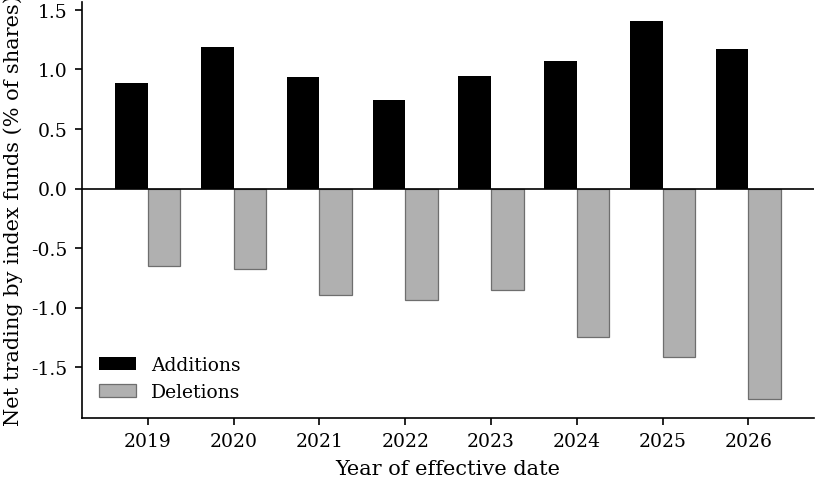

,mean Additions,mean Deletions,size Additions,size Deletions
year,,,,
2019,0.889,-0.646,10,14
2020,1.188,-0.671,25,13
2021,0.933,-0.894,17,16
2022,0.745,-0.939,29,21
2023,0.948,-0.849,13,17
2024,1.072,-1.249,17,15
2025,1.405,-1.413,17,12
2026,1.172,-1.767,11,12


In [30]:
f1 = e5.groupby(["year", "type"]).nt.agg(["mean", "size"]).unstack()
fig, ax = plt.subplots(figsize=(6.3, 3.6))
yrs = f1.index.values
w = 0.38
ax.bar(yrs - w / 2, f1[("mean", "addition")], w, color=PALETTE[0], label="Additions")
ax.bar(yrs + w / 2, f1[("mean", "deletion")], w, color=PALETTE[2], edgecolor=PALETTE[1], linewidth=0.6, label="Deletions")
ax.axhline(0, color=PALETTE[0], linewidth=0.8)
ax.set_xticks(yrs)
ax.set_xlabel("Year of effective date")
ax.set_ylabel("Net trading by index funds (% of shares)")
ax.legend(loc="lower left")
fig_save(fig, "fig_01_nettrading", "Mean net trading by index funds around OMXSB changes, by year (anchor Figure 1)")
f1.columns = [f"{a} {LABELS[b]}" for a, b in f1.columns]
f1.round(3).to_csv(os.path.join(FIG, "fig_01_nettrading.csv"))
f1.round(3)

Figure 3

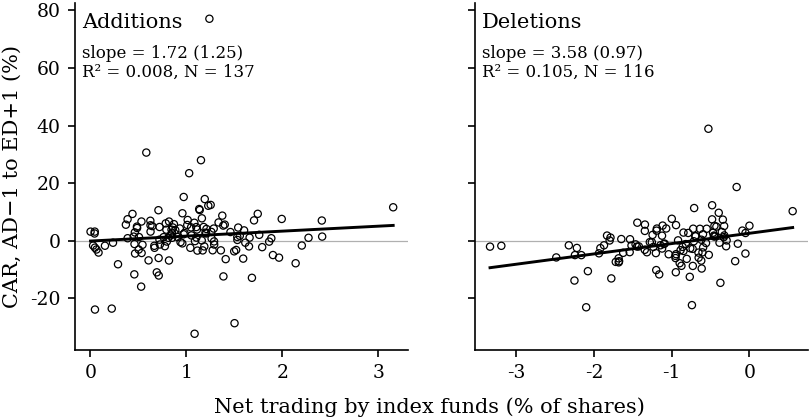

,a,c,se_c_hc1,p_c_hc1,r2,N
type,,,,,,
addition,-0.070,1.720,1.253,0.17,0.008,137
deletion,2.626,3.577,0.969,0.00,0.105,116


In [31]:
fig, axs = plt.subplots(1, 2, figsize=(6.3, 3.0), sharey=True)
f3 = []
for ax, typ in zip(axs, ["addition", "deletion"]):
    s = e5[(e5.type == typ)].dropna(subset=["nt", "tot"])
    m = sm.OLS(s.tot.values, sm.add_constant(s.nt.values)).fit(cov_type="HC1")
    ax.scatter(s.nt, s.tot, s=12, facecolors="none", edgecolors=PALETTE[0], linewidths=0.6)
    xs = np.linspace(s.nt.min(), s.nt.max(), 50)
    ax.plot(xs, m.params[0] + m.params[1] * xs, color=PALETTE[0])
    ax.axhline(0, color=PALETTE[2], linewidth=0.6, zorder=0)
    ax.text(0.02, 0.97, LABELS[typ], transform=ax.transAxes, va="top", ha="left")
    ax.text(0.02, 0.88, f"slope = {m.params[1]:.2f} ({m.bse[1]:.2f})\nR² = {m.rsquared:.3f}, N = {int(m.nobs)}", transform=ax.transAxes, va="top", ha="left", fontsize=8)
    f3.append(dict(type=typ, a=m.params[0], c=m.params[1], se_c_hc1=m.bse[1], p_c_hc1=m.pvalues[1], r2=m.rsquared, N=int(m.nobs)))
axs[0].set_ylabel("CAR, AD−1 to ED+1 (%)")
fig.supxlabel("Net trading by index funds (% of shares)", fontsize=10, y=-0.04)
fig_save(fig, "fig_03_scatter", "Cumulative abnormal return against net trading by index funds, one point per event (anchor Figure 3)")
f3 = pd.DataFrame(f3).set_index("type")
f3.to_csv(os.path.join(FIG, "fig_03_scatter.csv"))
NUM["fig3_slope_addition"] = round(float(f3.c["addition"]), 3)
NUM["fig3_slope_deletion"] = round(float(f3.c["deletion"]), 3)
f3.round(3)

Table 4

In [32]:
t4 = e5.groupby(["type", "year"])[["nt", "instbuy", "activebuy"]].median()
t4["N"] = e5.groupby(["type", "year"]).size()
ew = t4.groupby(level=0)[["nt", "instbuy", "activebuy"]].mean()
ew["N"] = t4.groupby(level=0).N.sum()
ew.index = pd.MultiIndex.from_tuples([(t, "Equal-weighted mean") for t in ew.index])
t4 = pd.concat([t4, ew]).sort_index()
t4 = t4.rename(index={"addition": "Panel A: Additions", "deletion": "Panel B: Deletions"}, level=0)
t4.index = pd.MultiIndex.from_tuples([(a, str(b)) for a, b in t4.index])
t4 = t4.rename(columns={"nt": "Index funds", "instbuy": "All funds", "activebuy": "Non-index funds"})
t4body = t4.copy()
for c in ["Index funds", "All funds", "Non-index funds"]:
    t4body[c] = t4body[c].map(lambda x: f"{x:.2f}")
t4body["N"] = t4body["N"].astype(int).astype(str)
tab_save(mt.MTable(t4body, rgroup_sep="t", notes="Median across events in each year of net trading from the last quarter-end before the announcement to the first quarter-end after the effective date, in percent of shares outstanding, for OMXSB index trackers, all FI-reporting funds, and funds that are not index trackers. The last row of each panel is the equal-weighted mean of the yearly medians. Years refer to the effective date; events before 2019 are not covered by the FI holdings data (first quarter 2018Q4), so the periods 2007–2012 and 2013–2017 have no rows."), "tab_04_institutions", "Median net trading by fund type and year (anchor institutions table)", t4.round(3))

Index funds 
 All funds 
 Non-index funds 
 N 
 
 
 
 
 Panel A: Additions 
 
 
 2019 
 0.93 
 0.89 
 0.12 
 10 
 
 
 2020 
 1.12 
 1.72 
 0.51 
 25 
 
 
 2021 
 0.82 
 1.01 
 0.00 
 17 
 
 
 2022 
 0.78 
 1.03 
 0.08 
 29 
 
 
 2023 
 0.99 
 0.67 
 -0.04 
 13 
 
 
 2024 
 1.04 
 1.20 
 0.33 
 17 
 
 
 2025 
 1.50 
 1.46 
 0.20 
 17 
 
 
 2026 
 1.24 
 1.17 
 0.06 
 11 
 
 
 Equal-weighted mean 
 1.05 
 1.14 
 0.16 
 139 
 
 
 Panel B: Deletions 
 
 
 2019 
 -0.56 
 -0.53 
 -0.11 
 14 
 
 
 2020 
 -0.73 
 -0.52 
 -0.05 
 13 
 
 
 2021 
 -0.73 
 -0.96 
 0.06 
 16 
 
 
 2022 
 -0.85 
 -0.89 
 -0.03 
 21 
 
 
 2023 
 -0.90 
 -0.39 
 0.12 
 17 
 
 
 2024 
 -1.07 
 -0.98 
 0.00 
 15 
 
 
 2025 
 -1.53 
 -1.96 
 -0.48 
 12 
 
 
 2026 
 -2.02 
 -2.48 
 -0.36 
 12 
 
 
 Equal-weighted mean 
 -1.05 
 -1.09 
 -0.11 
 120 
 
 
 Median across events in each year of net trading from the last quarter-end before the announcement to the first quarter-end after the effective date, in percent of shares outstanding, for OMXSB index trackers, all FI-reporting funds, and funds that are not index trackers. The last row of each panel is the equal-weighted mean of the yearly medians. Years refer to the effective date; events before 2019 are not covered by the FI holdings data (first quarter 2018Q4), so the periods 2007–2012 and 2013–2017 have no rows.

Table 5

In [33]:
def eta_boot(s, col="tot", B=9999, seed=1):
    g = s.groupby("adx").agg(nt=("nt", "sum"), y=(col, "sum"), n=("nt", "size"))
    G = len(g)
    rng = np.random.default_rng(seed)
    ii = rng.integers(0, G, size=(B, G))
    et = -g.nt.values[ii].sum(1) / g.y.values[ii].sum(1)
    return np.nanpercentile(et, 2.5), np.nanpercentile(et, 97.5), G
def eta_rows(sub, key):
    rows = []
    for p in PER + ["All"]:
        s = (sub[sub.period == p] if p != "All" else sub).dropna(subset=["nt", "tot", "eff"])
        if len(s) == 0:
            continue
        lo, hi, G = eta_boot(s)
        lo_e, hi_e, _ = eta_boot(s, "eff")
        rows.append(dict(panel=key, period=p, N=len(s), G=G, mean_nt=s.nt.mean(), mean_tot=s.tot.mean(), eta=-s.nt.mean() / s.tot.mean(), ci_lo=lo, ci_hi=hi, mean_eff=s.eff.mean(), eta_eff=-s.nt.mean() / s.eff.mean(), ci_lo_eff=lo_e, ci_hi_eff=hi_e))
    return rows
ad5 = e5[e5.type == "addition"].dropna(subset=["nt", "tot", "indexown"]).copy()
med = ad5.indexown.median()
print("periods without FI holdings data (before 2018Q4) have no rows in Table 5: " + ", ".join(p for p in PER if not (e5.period == p).any()))
rows = eta_rows(e5[e5.type == "addition"], "Panel A: Additions") + eta_rows(e5[e5.type == "deletion"], "Panel B: Deletions") + eta_rows(ad5[ad5.indexown <= med], "Panel C: Additions, index ownership at or below median") + eta_rows(ad5[ad5.indexown > med], "Panel D: Additions, index ownership above median")
t5 = pd.DataFrame(rows)
t5.to_csv(os.path.join(TAB, "tab_05_elasticity_long.csv"), index=False)
NUM["eta_all_addition"] = round(float(t5[(t5.panel == "Panel A: Additions") & (t5.period == "All")].eta.iloc[0]), 3)
NUM["eta_all_deletion"] = round(float(t5[(t5.panel == "Panel B: Deletions") & (t5.period == "All")].eta.iloc[0]), 3)
NUM["indexown_median_additions"] = round(float(med), 3)
t5w = pd.DataFrame({"N": t5.N.astype(str), "Clusters": t5.G.astype(str), "Mean net trading (%)": t5.mean_nt.map(lambda x: f"{x:.2f}"), "Mean CAR (%)": t5.mean_tot.map(lambda x: f"{x:.2f}"), "η": t5.eta.map(lambda x: f"{x:.2f}"), "95% interval": [f"[{a:.2f}, {b:.2f}]" for a, b in zip(t5.ci_lo, t5.ci_hi)], "Mean CAR, ED window (%)": t5.mean_eff.map(lambda x: f"{x:.2f}"), "η, ED window": t5.eta_eff.map(lambda x: f"{x:.2f}"), "95% interval, ED window": [f"[{a:.2f}, {b:.2f}]" for a, b in zip(t5.ci_lo_eff, t5.ci_hi_eff)]})
nonfin = [f"{p}, {q}" for p, q, a, b in zip(t5.panel, t5.period, t5.eta, t5.eta_eff) if not (np.isfinite(a) and np.isfinite(b))]
nonfin_note = (" The point estimate is not finite (mean CAR equal to zero) for: " + "; ".join(nonfin) + ".") if nonfin else " All point estimates are finite."
t5w.index = pd.MultiIndex.from_arrays([t5.panel, t5.period])
tab_save(mt.MTable(t5w, rgroup_sep="t", notes="Extension, not in the anchor paper. η = −mean(NetTrading)/mean(CAR) by period and type, with net trading by index funds in percent of shares outstanding and the cumulative abnormal return from AD−1 to ED+1 in percent. The interval is a percentile bootstrap that resamples announcement dates with replacement, 9,999 draws; it is wide or unbounded when the resampled mean CAR crosses zero. The last three columns repeat the calculation with the CAR over the effective-date window [ED−1, ED+1] in place of the total window, with the same bootstrap draws. Panels C and D split additions at the median pre-announcement index-fund ownership, the analog of the anchor paper's migrations in which index funds already held the stock." + nonfin_note), "tab_05_elasticity", "Price elasticity from index-fund net trading and CAR by period (anchor elasticity table)", t5.round(4))

periods without FI holdings data (before 2018Q4) have no rows in Table 5: 2007–2012, 2013–2017


N 
 Clusters 
 Mean net trading (%) 
 Mean CAR (%) 
 η 
 95% interval 
 Mean CAR, ED window (%) 
 η, ED window 
 95% interval, ED window 
 
 
 
 
 Panel A: Additions 
 
 
 2018–2020 
 34 
 4 
 1.10 
 2.35 
 -0.47 
 [-1.57, -0.20] 
 1.80 
 -0.61 
 [-1.08, -0.44] 
 
 
 2021–2023 
 58 
 6 
 0.84 
 0.57 
 -1.46 
 [-10.95, 15.15] 
 -0.59 
 1.43 
 [-12.64, 12.86] 
 
 
 2024–2026 
 45 
 5 
 1.22 
 2.67 
 -0.46 
 [-0.82, -0.30] 
 -0.03 
 38.75 
 [-21.76, 38.75] 
 
 
 All 
 137 
 15 
 1.03 
 1.70 
 -0.61 
 [-1.23, -0.38] 
 0.19 
 -5.54 
 [-33.92, 36.43] 
 
 
 Panel B: Deletions 
 
 
 2018–2020 
 26 
 4 
 -0.66 
 1.70 
 0.39 
 [-0.66, 3.71] 
 1.65 
 0.40 
 [-1.83, 2.31] 
 
 
 2021–2023 
 52 
 6 
 -0.90 
 -1.29 
 -0.69 
 [-6.43, 9.09] 
 -0.36 
 -2.48 
 [-16.68, 21.22] 
 
 
 2024–2026 
 38 
 5 
 -1.46 
 -2.62 
 -0.56 
 [-4.40, 2.96] 
 -2.04 
 -0.72 
 [-2.51, -0.48] 
 
 
 All 
 116 
 15 
 -1.03 
 -1.06 
 -0.97 
 [-8.97, 9.48] 
 -0.46 
 -2.23 
 [-18.83, 17.64] 
 
 
 Panel C: Additions, index ownership at or below median 
 
 
 2018–2020 
 17 
 4 
 1.17 
 1.11 
 -1.06 
 [-2.96, 997.48] 
 2.15 
 -0.54 
 [-1.12, -0.41] 
 
 
 2021–2023 
 40 
 6 
 0.80 
 1.09 
 -0.74 
 [-7.29, 5.31] 
 -1.15 
 0.70 
 [-10.68, 4.76] 
 
 
 2024–2026 
 43 
 5 
 1.23 
 2.66 
 -0.46 
 [-0.82, -0.29] 
 -0.08 
 15.50 
 [-23.56, 22.65] 
 
 
 All 
 100 
 15 
 1.05 
 1.76 
 -0.59 
 [-1.98, -0.34] 
 -0.13 
 8.08 
 [-28.12, 28.49] 
 
 
 Panel D: Additions, index ownership above median 
 
 
 2018–2020 
 17 
 4 
 1.03 
 3.60 
 -0.29 
 [-1.46, -0.14] 
 1.45 
 -0.71 
 [-1.11, -0.45] 
 
 
 2021–2023 
 18 
 5 
 0.93 
 -0.56 
 1.67 
 [-3.54, 12.95] 
 0.66 
 -1.42 
 [-3.22, 28.74] 
 
 
 2024–2026 
 2 
 1 
 1.14 
 2.97 
 -0.38 
 [-0.38, -0.38] 
 0.99 
 -1.15 
 [-1.15, -1.15] 
 
 
 All 
 37 
 10 
 0.99 
 1.54 
 -0.64 
 [-6.17, 5.65] 
 1.04 
 -0.95 
 [-4.71, 1.56] 
 
 
 Extension, not in the anchor paper. η = −mean(NetTrading)/mean(CAR) by period and type, with net trading by index funds in percent of shares outstanding and the cumulative abnormal return from AD−1 to ED+1 in percent. The interval is a percentile bootstrap that resamples announcement dates with replacement, 9,999 draws; it is wide or unbounded when the resampled mean CAR crosses zero. The last three columns repeat the calculation with the CAR over the effective-date window [ED−1, ED+1] in place of the total window, with the same bootstrap draws. Panels C and D split additions at the median pre-announcement index-fund ownership, the analog of the anchor paper's migrations in which index funds already held the stock. All point estimates are finite.

Figure 8

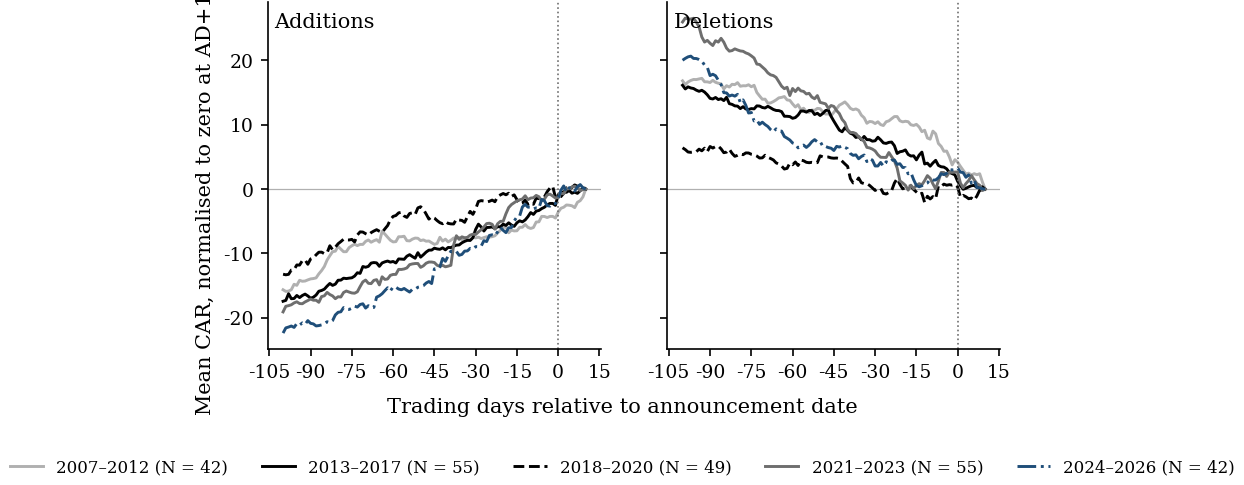

addition                                          deletion                                        
     2007–2012 2013–2017 2018–2020 2021–2023 2024–2026 2007–2012 2013–2017 2018–2020 2021–2023 2024–2026
-100    -15.64    -17.43    -13.22    -19.08    -22.37     16.84     16.15      6.43     25.98     20.04
-50      -7.99    -10.57     -2.73    -12.16    -15.16     12.51     11.45      5.18     13.49      7.42
-20      -5.98     -5.44     -0.68     -5.00     -6.40     10.46      5.90      0.05      0.97      3.37
-5       -4.25     -2.81     -1.20     -1.53     -1.81      5.88      3.43      0.78      2.59      2.26
-1       -4.49     -2.52     -1.27     -1.38     -2.25      4.58      2.23      0.72      2.66      3.05
 0       -3.58     -0.86     -1.12     -1.29     -1.45      4.19      1.21      0.34      2.66      3.31
 1       -2.97     -0.53     -1.15     -0.64     -0.16      3.54      0.56     -1.26      0.94      2.65
 5       -2.59     -0.63      0.27      0.35      0.21      2.20      0.53     -1.39      2.11      0.92
 10       0.00      0.00      0.00      0.00      0.00      0.00      0.00      0.00      0.00      0.00

In [34]:
def cum_paths(A, idx, lo, hi, zero_at=None):
    paths = []
    for r, i in idx:
        s = A[r].iloc[i + lo:i + hi + 1]
        if len(s) == hi - lo + 1 and not s.isna().any():
            c = s.cumsum().values
            if zero_at is not None:
                c = c - c[zero_at]
            paths.append(c)
    return np.array(paths)
def car_fig(anchor, lo, hi, zero_at, name, xlabel, ylabel, desc, legend_loc):
    fig, axs = plt.subplots(1, 2, figsize=(6.3, 3.0), sharey=True)
    data = {}
    x = np.arange(lo, hi + 1)
    for ax, typ in zip(axs, ["addition", "deletion"]):
        for p, ls in zip(PER, LS):
            s = ev[(ev.type == typ) & (ev.period == p)]
            P = cum_paths(AR, zip(s.RIC, s[anchor]), lo, hi, zero_at)
            ax.plot(x, P.mean(0), label=f"{p} (N = {len(P)})", **ls)
            data[(typ, p)] = pd.Series(P.mean(0), index=x)
        ax.axvline(0, color=PALETTE[1], linewidth=0.8, linestyle=":")
        ax.axhline(0, color=PALETTE[2], linewidth=0.6, zorder=0)
        ax.text(0.02, 0.97, LABELS[typ], transform=ax.transAxes, va="top", ha="left")
        ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    axs[0].set_ylabel(ylabel)
    fig.supxlabel(xlabel, fontsize=10, y=-0.04)
    h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=len(PER), fontsize=8)
    fig_save(fig, name, desc)
    data = pd.DataFrame(data)
    data.to_csv(os.path.join(FIG, name + ".csv"))
    return data
f8 = car_fig("iAD", -100, 10, 110, "fig_08_car_announcement", "Trading days relative to announcement date", "Mean CAR, normalised to zero at AD+10 (%)", "Mean cumulative abnormal return from AD−100 to AD+10 by period, normalised to zero at AD+10 (anchor Figure 8)", None)
f8.loc[[-100, -50, -20, -5, -1, 0, 1, 5, 10]].round(2)

Pre-announcement table

In [35]:
rows = []
for typ in ["addition", "deletion"]:
    s = ev[ev.type == typ]
    for n0 in [-100, -50, -20, -10]:
        for end in [-1, 10]:
            y = pd.Series([wsum(AR, r, a + n0, a + end) for r, a in zip(s.RIC, s.iAD)], index=s.index)
            for p in PER + ["All"]:
                m, se, N = hc1(y[s.period == p] if p != "All" else y)
                rows.append(dict(type=typ, start=n0, end=end, period=p, mean=m, se_hc1=se, N=N))
t8 = pd.DataFrame(rows)
t8.to_csv(os.path.join(TAB, "tab_08_preannouncement_long.csv"), index=False)
t8["c"] = [f"{m:.2f}{star(2 * stats.norm.sf(abs(m / se)))}\n({se:.2f})\n[{N}]" if np.isfinite(se) else "" for m, se, N in zip(t8["mean"], t8.se_hc1, t8.N)]
t8["window"] = [f"[AD−{-a}, AD{'−1' if b == -1 else '+10'}]" for a, b in zip(t8.start, t8.end)]
t8w = t8.pivot(index=["type", "window"], columns="period", values="c").reindex(columns=PER + ["All"])
t8w = t8w.reindex(pd.MultiIndex.from_product([["addition", "deletion"], list(dict.fromkeys(t8.window))]))
t8w.index = pd.MultiIndex.from_tuples([({"addition": "Panel A: Additions", "deletion": "Panel B: Deletions"}[a], b) for a, b in t8w.index])
tab_save(mt.MTable(t8w, rgroup_sep="t", notes="Mean cumulative abnormal return in percent from n trading days before the announcement date to the day before it, and from n days before to ten days after it, for n = 100, 50, 20 and 10, by period of the effective date and over all periods. HC1 standard errors in parentheses and the number of events with a complete window in brackets; stars from the HC1 p-value: " + STARS), "tab_08_preannouncement", "Cumulative pre-announcement abnormal returns by period (anchor pre-announcement table)", t8.drop(columns="c").round(4))

2007–2012 
 2013–2017 
 2018–2020 
 2021–2023 
 2024–2026 
 All 
 
 
 
 
 Panel A: Additions 
 
 
 [AD−100, AD−1] 
 11.64*** (2.78) [42] 
 15.54*** (4.02) [55] 
 12.67*** (2.26) [49] 
 17.55*** (4.52) [55] 
 20.04** (8.34) [42] 
 15.52*** (2.09) [243] 
 
 
 [AD−100, AD+10] 
 16.13*** (3.07) [42] 
 18.06*** (4.28) [55] 
 13.93*** (2.38) [49] 
 18.93*** (4.72) [55] 
 22.29** (9.47) [42] 
 17.82*** (2.28) [243] 
 
 
 [AD−50, AD−1] 
 3.01 (2.15) [47] 
 6.23* (3.23) [57] 
 1.30 (1.82) [51] 
 10.32*** (3.73) [56] 
 12.28 (7.95) [45] 
 6.62*** (1.85) [256] 
 
 
 [AD−50, AD+10] 
 7.50*** (2.24) [46] 
 8.53** (3.59) [57] 
 3.16 (1.98) [50] 
 11.79*** (4.02) [56] 
 14.51 (9.05) [45] 
 9.06*** (2.07) [254] 
 
 
 [AD−20, AD−1] 
 1.11 (1.67) [48] 
 2.87* (1.54) [57] 
 -0.53 (1.53) [51] 
 3.40** (1.47) [56] 
 3.33 (2.18) [45] 
 2.06*** (0.74) [257] 
 
 
 [AD−20, AD+10] 
 5.81*** (1.72) [46] 
 5.16*** (1.87) [57] 
 1.22 (1.77) [50] 
 4.87** (1.89) [56] 
 5.56* (3.25) [45] 
 4.51*** (0.95) [254] 
 
 
 [AD−10, AD−1] 
 0.60 (0.91) [48] 
 1.86* (0.98) [57] 
 1.47 (1.10) [51] 
 0.11 (1.11) [56] 
 0.84 (1.03) [45] 
 0.99** (0.46) [257] 
 
 
 [AD−10, AD+10] 
 5.35*** (1.17) [46] 
 4.15*** (1.30) [57] 
 2.74* (1.64) [50] 
 1.58 (1.72) [56] 
 3.06 (2.06) [45] 
 3.33*** (0.71) [254] 
 
 
 Panel B: Deletions 
 
 
 [AD−100, AD−1] 
 -12.04*** (3.90) [56] 
 -14.32*** (5.24) [33] 
 -6.88* (3.93) [39] 
 -24.09*** (3.41) [53] 
 -16.99*** (4.00) [35] 
 -15.21*** (1.84) [216] 
 
 
 [AD−100, AD+10] 
 -16.61*** (4.20) [56] 
 -16.54*** (5.44) [33] 
 -7.33** (3.55) [38] 
 -26.75*** (3.77) [53] 
 -20.04*** (4.16) [35] 
 -18.02*** (1.93) [215] 
 
 
 [AD−50, AD−1] 
 -7.97*** (2.59) [56] 
 -9.11*** (3.16) [36] 
 -3.65 (3.20) [39] 
 -11.88*** (2.39) [53] 
 -4.47* (2.50) [39] 
 -7.72*** (1.23) [223] 
 
 
 [AD−50, AD+10] 
 -12.55*** (3.00) [56] 
 -11.99*** (3.39) [36] 
 -4.13 (2.87) [38] 
 -14.54*** (2.67) [53] 
 -7.26*** (2.58) [39] 
 -10.56*** (1.33) [222] 
 
 
 [AD−20, AD−1] 
 -5.90*** (1.73) [57] 
 -3.23* (1.87) [36] 
 -0.17 (2.12) [39] 
 1.37 (3.60) [53] 
 -1.22 (2.11) [39] 
 -1.94* (1.14) [224] 
 
 
 [AD−20, AD+10] 
 -10.48*** (2.23) [57] 
 -6.11*** (2.02) [36] 
 -0.76 (2.29) [38] 
 -1.29 (3.59) [53] 
 -4.00* (2.24) [39] 
 -4.80*** (1.23) [223] 
 
 
 [AD−10, AD−1] 
 -3.56*** (1.22) [58] 
 -1.04 (1.57) [36] 
 1.73 (1.18) [39] 
 0.56 (2.46) [53] 
 2.11** (0.99) [39] 
 -0.29 (0.76) [225] 
 
 
 [AD−10, AD+10] 
 -8.14*** (1.65) [58] 
 -3.92** (1.77) [36] 
 1.11 (1.77) [38] 
 -2.10 (2.45) [53] 
 -0.67 (1.11) [39] 
 -3.17*** (0.88) [224] 
 
 
 Mean cumulative abnormal return in percent from n trading days before the announcement date to the day before it, and from n days before to ten days after it, for n = 100, 50, 20 and 10, by period of the effective date and over all periods. HC1 standard errors in parentheses and the number of events with a complete window in brackets; stars from the HC1 p-value: * p<0.10, ** p<0.05, *** p<0.01.

Figure 9

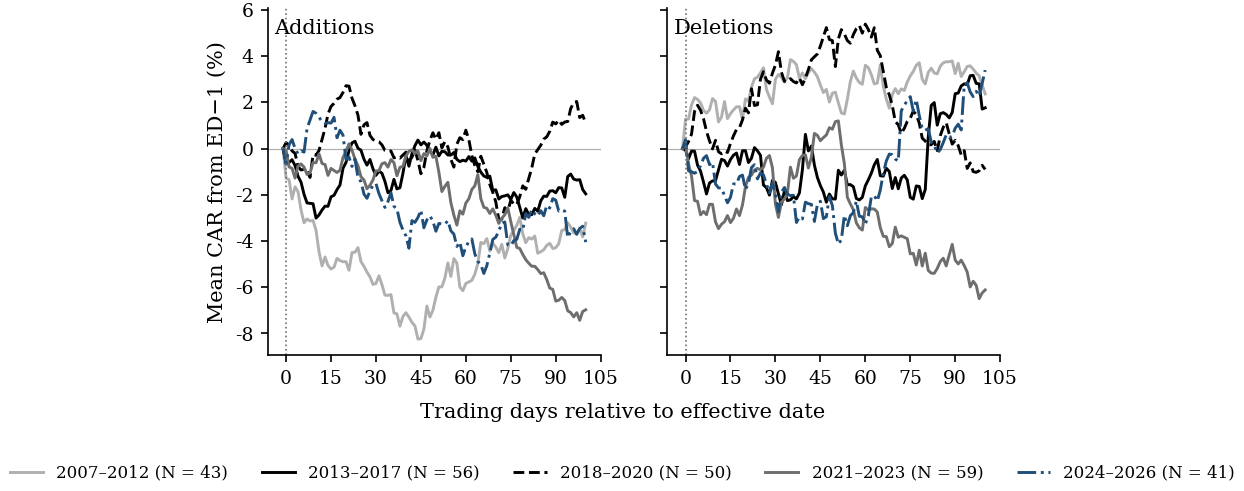

addition                                          deletion                                        
     2007–2012 2013–2017 2018–2020 2021–2023 2024–2026 2007–2012 2013–2017 2018–2020 2021–2023 2024–2026
-1        0.00      0.00      0.00      0.00      0.00      0.00      0.00      0.00      0.00      0.00
 0       -1.28     -0.62      0.26     -0.07     -0.68      1.28     -0.06      0.07      0.15      0.38
 1       -1.35     -0.60      0.15     -0.79      0.17      1.28     -0.44      0.31     -0.67     -0.97
 5       -2.66     -1.46     -0.93     -0.66     -0.09      1.98     -0.97      1.66     -2.87     -0.74
 10      -3.54     -3.01     -0.29     -0.62      1.53      2.04     -1.39      0.35     -3.17     -1.54
 20      -4.89     -0.60      2.72     -0.12     -0.48      2.15     -0.09      1.75     -1.64     -1.77
 50      -6.44      0.06      0.40     -0.33     -3.58      2.44     -2.19      3.55      1.16     -3.66
 100     -3.23     -1.96      1.10     -6.98     -4.05      2.37      1.76     -0.90     -6.12      3.39

In [36]:
f9 = car_fig("iED", -1, 100, 0, "fig_09_car_effective", "Trading days relative to effective date", "Mean CAR from ED−1 (%)", "Mean cumulative abnormal return from ED−1 to ED+100 by period (anchor Figure 9)", None)
f9.loc[[-1, 0, 1, 5, 10, 20, 50, 100]].round(2)

Figure 10

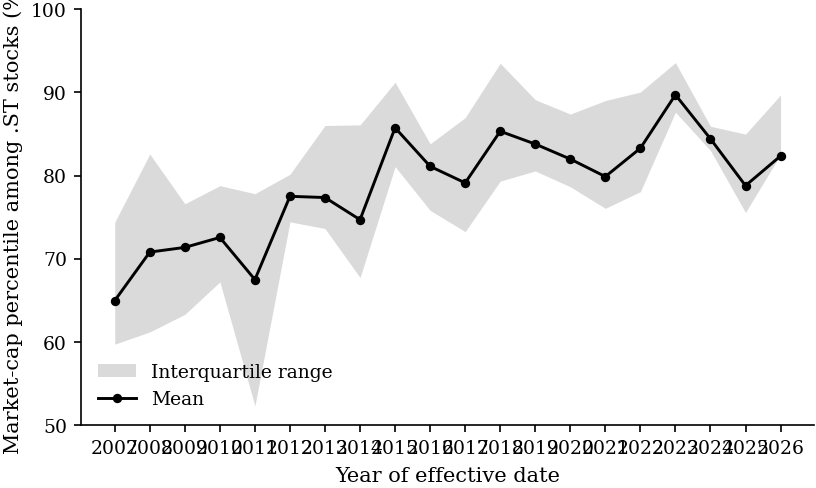

,mean,q25,q75,N
year,,,,
2007,65.0,59.7,74.4,3
2008,70.8,61.2,82.6,8
2009,71.4,63.3,76.6,9
2010,72.6,67.2,78.8,6
2011,67.5,52.3,77.8,10
2012,77.5,74.4,80.2,12
2013,77.4,73.6,86.0,8
2014,74.7,67.7,86.1,7
2015,85.7,81.1,91.2,11


In [37]:
mcm = px.groupby(["ric", "ym"]).mcap.last().reset_index()
mcm = mcm[mcm.mcap > 0]
mcm["pct"] = mcm.groupby("ym").mcap.rank(pct=True) * 100
adds = ev[ev.type == "addition"].merge(mcm.rename(columns={"ric": "RIC", "ym": "ym_pre"}), on=["RIC", "ym_pre"], how="left")
adds["year"] = adds.ED.dt.year
f10 = adds.groupby("year").pct.agg(mean="mean", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75), N="count")
fig, ax = plt.subplots(figsize=(6.3, 3.6))
ax.fill_between(f10.index, f10.q25, f10.q75, color=PALETTE[1], alpha=0.25, linewidth=0, label="Interquartile range")
ax.plot(f10.index, f10["mean"], color=PALETTE[0], marker="o", markersize=3.5, label="Mean")
ax.set_xticks(f10.index)
ax.set_ylim(50, 100)
ax.set_xlabel("Year of effective date")
ax.set_ylabel("Market-cap percentile among .ST stocks (%)")
ax.legend(loc="lower left")
fig_save(fig, "fig_10_size_rank", "Market-cap percentile rank of added stocks in the month before the announcement, by year (anchor Figure 10)")
f10.to_csv(os.path.join(FIG, "fig_10_size_rank.csv"))
f10.round(1)

Figure 11

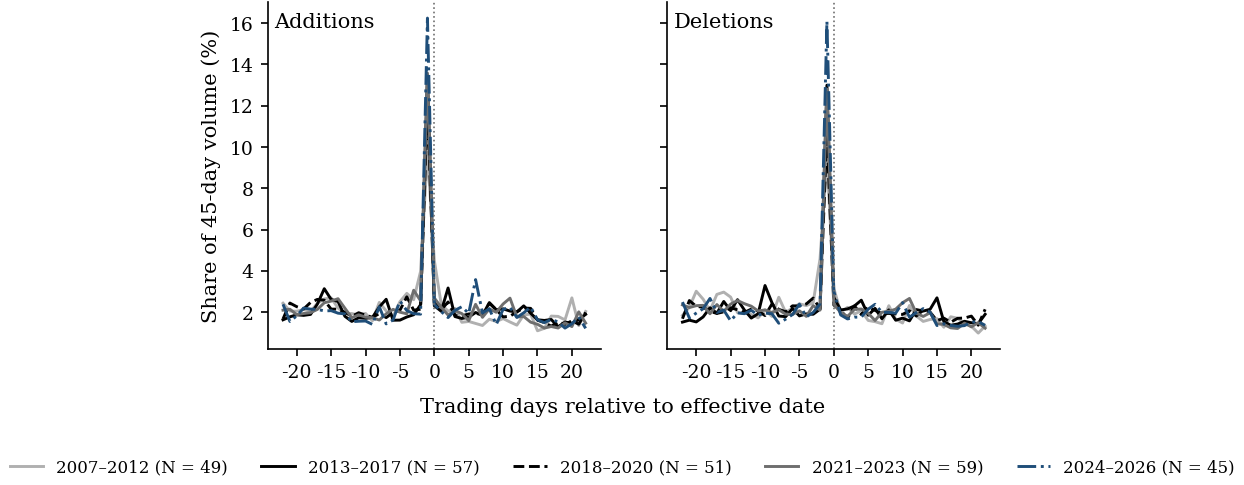

N 
 ED−1 
 ED 
 ED+1 
 Other days, mean 
 
 
 
 
 Panel A: Additions 
 
 
 2007–2012 
 49 
 9.73 
 4.50 
 2.39 
 1.99 
 
 
 2013–2017 
 57 
 13.49 
 2.31 
 2.04 
 1.96 
 
 
 2018–2020 
 51 
 12.23 
 2.45 
 2.11 
 1.98 
 
 
 2021–2023 
 59 
 13.58 
 2.68 
 2.24 
 1.95 
 
 
 2024–2026 
 45 
 16.24 
 2.38 
 2.03 
 1.89 
 
 
 Panel B: Deletions 
 
 
 2007–2012 
 58 
 9.41 
 3.15 
 2.00 
 2.03 
 
 
 2013–2017 
 36 
 12.99 
 2.71 
 2.10 
 1.96 
 
 
 2018–2020 
 39 
 10.77 
 2.34 
 2.08 
 2.02 
 
 
 2021–2023 
 54 
 12.81 
 2.39 
 1.97 
 1.97 
 
 
 2024–2026 
 39 
 16.09 
 3.01 
 1.86 
 1.88 
 
 
 Share of the total volume traded from ED−22 to ED+22 that falls on the day before, on, and after the effective date, averaged across events in each period, in percent. The anchor paper's bid-ask spread analysis is not replicated because bid and ask quotes are not available in the data.

In [38]:
vo = px.pivot(index="date", columns="ric", values="volume").reindex(cal)
def vshare(ric, i):
    s = vo[ric].iloc[i - 22:i + 23]
    if len(s) < 45 or s.isna().all():
        return None
    s = s.fillna(0.0)
    return s.values / s.sum() * 100 if s.sum() > 0 else None
fig, axs = plt.subplots(1, 2, figsize=(6.3, 3.0), sharey=True)
f11, rows = {}, []
x = np.arange(-22, 23)
for ax, typ in zip(axs, ["addition", "deletion"]):
    for p, ls in zip(PER, LS):
        s = ev[(ev.type == typ) & (ev.period == p)]
        P = np.array([v for v in (vshare(r, i) for r, i in zip(s.RIC, s.iED)) if v is not None])
        m = P.mean(0)
        ax.plot(x, m, label=f"{p} (N = {len(P)})", **ls)
        f11[(typ, p)] = pd.Series(m, index=x)
        rows.append(dict(type=typ, period=p, N=len(P), share_EDm1=m[21], share_ED=m[22], share_EDp1=m[23], avg_other_day=np.delete(m, [21, 22]).mean()))
    ax.axvline(0, color=PALETTE[1], linewidth=0.8, linestyle=":")
    ax.text(0.02, 0.97, LABELS[typ], transform=ax.transAxes, va="top", ha="left")
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
axs[0].set_ylabel("Share of 45-day volume (%)")
fig.supxlabel("Trading days relative to effective date", fontsize=10, y=-0.04)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=len(PER), fontsize=8)
fig_save(fig, "fig_11_volume", "Share of volume traded on each day from ED−22 to ED+22 by period (anchor Figure 11)")
pd.DataFrame(f11).to_csv(os.path.join(FIG, "fig_11_volume.csv"))
t11 = pd.DataFrame(rows)
NUM["volume_share_EDm1_mean"] = round(float(t11.share_EDm1.mean()), 2)
t11w = pd.DataFrame({"N": t11.N.astype(str), "ED−1": t11.share_EDm1.map(lambda x: f"{x:.2f}"), "ED": t11.share_ED.map(lambda x: f"{x:.2f}"), "ED+1": t11.share_EDp1.map(lambda x: f"{x:.2f}"), "Other days, mean": t11.avg_other_day.map(lambda x: f"{x:.2f}")})
t11w.index = pd.MultiIndex.from_arrays([t11.type.map({"addition": "Panel A: Additions", "deletion": "Panel B: Deletions"}), t11.period])
tab_save(mt.MTable(t11w, rgroup_sep="t", notes="Share of the total volume traded from ED−22 to ED+22 that falls on the day before, on, and after the effective date, averaged across events in each period, in percent. The anchor paper's bid-ask spread analysis is not replicated because bid and ask quotes are not available in the data."), "tab_06_volume_share", "Share of 45-day volume on the days around the effective date, by period", t11.round(4))

In [39]:
if {"bid", "ask"}.issubset(px.columns):
    bw = px.pivot(index="date", columns="ric", values="bid").reindex(cal)
    aw = px.pivot(index="date", columns="ric", values="ask").reindex(cal)
    rs = ((aw - bw) / ((aw + bw) / 2) * 100).where((bw > 0) & (aw >= bw))
    def sp_at(ric, i):
        return rs.at[cal[i - 1], ric] if ric in rs.columns and i >= 1 else np.nan
    ev["spread_adm1"] = [sp_at(r, i) for r, i in zip(ev.RIC, ev.iAD)]
    ev["spread_edm1"] = [sp_at(r, i) for r, i in zip(ev.RIC, ev.iED)]
    t7 = ev.groupby(["type", "period"]).agg(N_AD=("spread_adm1", "count"), spread_ADm1=("spread_adm1", "median"), N_ED=("spread_edm1", "count"), spread_EDm1=("spread_edm1", "median")).reset_index()
    t7w = pd.DataFrame({"N, AD−1": t7.N_AD.astype(str), "Spread at AD−1 (%)": t7.spread_ADm1.map(lambda x: f"{x:.2f}"), "N, ED−1": t7.N_ED.astype(str), "Spread at ED−1 (%)": t7.spread_EDm1.map(lambda x: f"{x:.2f}")})
    t7w.index = pd.MultiIndex.from_arrays([t7.type.map({"addition": "Panel A: Additions", "deletion": "Panel B: Deletions"}), t7.period])
    NUM["spread_median_EDm1_all"] = round(float(ev.spread_edm1.median()), 3)
    tab_save(mt.MTable(t7w, rgroup_sep="t", notes="Median across events of the relative bid-ask spread, the closing ask minus the closing bid over their midpoint in percent, on the trading day before the announcement and on the trading day before the effective date, by period of the effective date. Events without a valid closing quote on the day are left out, so N can fall short of the event count."), "tab_07_spread", "Median relative bid-ask spread at AD−1 and ED−1 by period", t7.round(4))
    display(t7w)
else:
    print("tab_07_spread skipped: PANEL has no bid and ask columns")


N, AD−1 Spread at AD−1 (%) N, ED−1 Spread at ED−1 (%)
type               period                                                         
Panel A: Additions 2007–2012      42               0.61      42               0.45
                   2013–2017      55               0.26      55               0.34
                   2018–2020      50               0.23      50               0.27
                   2021–2023      56               0.17      56               0.19
                   2024–2026      45               0.18      45               0.25
Panel B: Deletions 2007–2012      51               0.43      51               0.47
                   2013–2017      35               0.33      35               0.34
                   2018–2020      38               0.19      38               0.22
                   2021–2023      54               0.21      54               0.21
                   2024–2026      38               0.21      38               0.17

Checks

In [40]:
chain = pd.DataFrame({"Step": ["Events in source file", "With price data in the LSEG panel", "After listing/delisting filter", "With a complete total-window CAR (no missing stock-day)", "Table 3, additions", "Table 3, deletions", "With a quarter-end before AD in FI data", "With at least one ISIN in FI data", "With net trading"], "N": [NUM["events_file"], NUM["events_raw"], len(ev), int(ev.tot.notna().sum()), NUM["t3_N_additions"], NUM["t3_N_deletions"], len(e5), int((e5.n_isin > 0).sum()), int(e5.nt.notna().sum())]}).set_index("Step")
NUM["events_part5"] = int(len(e5))
NUM["events_with_nettrading"] = int(e5.nt.notna().sum())
tab_save(mt.MTable(chain, notes="Number of events retained at each step of the construction."), "tabA_06_event_chain", "Event counts through the construction chain", chain)

N 
 
 
 
 
 Events in source file 
 536 
 
 
 With price data in the LSEG panel 
 505 
 
 
 After listing/delisting filter 
 487 
 
 
 With a complete total-window CAR (no missing stock-day) 
 481 
 
 
 Table 3, additions 
 229 
 
 
 Table 3, deletions 
 208 
 
 
 With a quarter-end before AD in FI data 
 259 
 
 
 With at least one ISIN in FI data 
 259 
 
 
 With net trading 
 253 
 
 
 Number of events retained at each step of the construction.

In [41]:
dr = drop[["event_id", "company", "type", "ED", "first_date", "last_date", "listed_100", "delisted_100"]].copy()
for c in ["ED", "first_date", "last_date"]:
    dr[c] = dr[c].dt.strftime("%Y-%m-%d")
dr["Reason"] = np.where(dr.listed_100, "Listed within 100 days before ED", "Delisted within 100 days after ED")
dr = dr.rename(columns={"event_id": "Event", "company": "Company", "type": "Type", "first_date": "First trading day", "last_date": "Last trading day"})[["Event", "Company", "Type", "ED", "First trading day", "Last trading day", "Reason"]].set_index("Event")
dr["Type"] = dr["Type"].map(LABELS)
tab_save(mt.MTable(dr, notes="Events removed because the stock was listed within 100 calendar days before, or delisted within 100 calendar days after, the effective date, using the first and last trading day in the LSEG panel."), "tabA_05_dropped_events", "Events dropped by the listing/delisting filter", dr)

,Company,Type,ED,First trading day,Last trading day,Reason
OMXSB-2008H2-09,HEXPOL AB ser. B,Deletions,2008-07-01,2008-06-09,2026-10-23,Listed within 100 days before ED
OMXSB-2009JAN-08,Loomis AB ser. B,Deletions,2009-01-02,2008-12-09,2026-10-23,Listed within 100 days before ED
OMXSB-2009JAN-12,Teleca AB ser. B,Deletions,2009-01-02,2004-07-01,2009-03-02,Delisted within 100 days after ED
OMXSB-2009JAN-14,Vostok Gas Ltd. SDB,Deletions,2009-01-02,2004-07-01,2009-01-30,Delisted within 100 days after ED
OMXSB-2014H1-02,Hemfosa Fastigheter AB,Additions,2014-06-02,2014-03-21,2020-01-31,Listed within 100 days before ED
OMXSB-2016H2-01,Ahlsell AB,Additions,2016-12-01,2016-10-28,2019-03-06,Listed within 100 days before ED
OMXSB-2017H1-01,Ambea AB,Additions,2017-06-01,2017-03-31,2026-10-23,Listed within 100 days before ED
OMXSB-2019H1-05,Nordic Entertainment Group ser. B,Additions,2019-06-03,2019-03-28,2026-10-26,Listed within 100 days before ED
OMXSB-2019H2-03,EQT AB,Additions,2019-12-02,2019-09-24,2026-10-23,Listed within 100 days before ED
OMXSB-2019H2-08,Hembla AB ser. B,Deletions,2019-12-02,2014-04-09,2020-01-10,Delisted within 100 days after ED


In [42]:
with open(os.path.join(OUT, "numbers.json"), "w") as f:
    json.dump(dict(sorted(NUM.items())), f, indent=2, ensure_ascii=False)
lines = ["# Exhibits manifest", "", "All exhibits are produced by code/notebooks/replication_omxsb_2007.ipynb (Greenwood–Sammon conventions: missing stock-days kept as NaN, AD and ED moved to the next trading day, uncentred controls, Figure 8 normalised at AD+10) from " + ", ".join(os.path.basename(f) for f in REQ) + " and the 31 Fondinnehav zip files (2018Q4 to 2026Q2). Tables are saved as .tex (booktabs fragment), .docx and .csv in output/tables; figures as .pdf and .png (300 dpi) with their plotted data as .csv in output/figures.", "", "| Exhibit | Files | Description |", "|---|---|---|"]
for name, desc in MAN:
    files = "tex, docx, csv" if name.startswith("tab") else "pdf, png, csv"
    lines.append(f"| {name} | {files} | {desc} |")
with open(os.path.join(OUT, "exhibits_manifest.md"), "w") as f:
    f.write("\n".join(lines) + "\n")
pd.DataFrame(MAN, columns=["exhibit", "description"])

,exhibit,description
0,tab_01_sample,Event counts by period before and after the pr...
1,tab_02_car,Abnormal returns around OMXSB changes by perio...
2,tabA_07_car_robustness,Table 2 under three alternative conventions: e...
3,tab_00_by_year,Event counts and mean CARs by year of the effe...
4,fig_02_by_year,Mean CAR by year of the effective date with a ...
5,tabA_08_sample_sensitivity,Total-window CAR with and without the listing/...
6,tabA_09_sample_selection,Sample selection by year (anchor Table A1 anal...
7,tab_03_determinants,Determinants of the index effect with period d...
8,tabA_02_isin_matches,ISIN name matches used to bridge ISIN changes ...
9,tabA_03_index_funds,Funds classified as OMXSB index trackers from ...
